In [ ]:
from google.colab import files

uploaded = files.upload()


Saving release_generation_yearly_global.csv to release_generation_yearly_global (2).csv


In [ ]:
import pandas as pd
ember = pd.read_csv("release_generation_yearly_global.csv")

print("Number of rows:", ember.shape[0])
print("Number of columns:", ember.shape[1])

print("\nColumn names:")
print(ember.columns.tolist())


Number of rows: 104241
Number of columns: 24

Column names:
['Area', 'ISO 3 code', 'Year', 'Area type', 'Electricity source', 'Is aggregated source', 'Generation (TWh)', 'Generation YoY change (TWh)', 'Generation YoY change (%)', 'Share of generation (%)', 'Share of generation YoY change (% points)', 'Capacity (GW)', 'Emissions (MtCO2e)', 'Emissions YoY change (MtCO2e)', 'Emissions YoY change (%)', 'Share of emissions (%)', 'Emissions intensity (gCO2e/kWh)', 'Continent', 'Ember region', 'EU member', 'OECD member', 'G20 member', 'G7 member', 'ASEAN member']


In [ ]:

print("Earliest year:", ember["Year"].min())
print("Latest year:", ember["Year"].max())

print("\nNumber of unique years:",
      ember["Year"].nunique())

print("\nAvailable years:")
print(sorted(ember["Year"].dropna().unique()))


Earliest year: 1985
Latest year: 2025

Number of unique years: 41

Available years:
[np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [ ]:

print("Unique areas:", ember["Area"].nunique())
print(ember["Area type"].value_counts())

print("\nContinents:")
print(ember["Continent"].value_counts())


Unique areas: 224
Area type
Country or economy    97975
Region                 6266
Name: count, dtype: int64

Continents:
Continent
Europe           23943
Asia             23311
Africa           23275
North America    14152
South America     6741
Oceania           6553
Name: count, dtype: int64


In [ ]:

print("Electricity sources:")

print(
    ember["Electricity source"]
    .value_counts(dropna=False)
    .to_string()
)


Electricity sources:
Electricity source
Demand                                   6305
Total generation                         6305
Fossil                                   6305
Other fossil                             6299
Hydro, bioenergy and other renewables    6298
Clean                                    6298
Renewables                               6298
Wind and solar                           6259
Solar                                    6237
Bioenergy                                6233
Hydro                                    6229
Coal                                     6189
Gas                                      6123
Wind                                     6047
Nuclear                                  5861
Net imports                              5632
Other renewables                         5323


In [ ]:

missing_report = pd.DataFrame({
    "Missing values": ember.isnull().sum(),
    "Missing percentage": (
        ember.isnull().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing percentage",
        ascending=False
    )
)


,Missing values,Missing percentage
Emissions YoY change (%),48746,46.76
Emissions intensity (gCO2e/kWh),40582,38.93
Generation YoY change (%),37028,35.52
Capacity (GW),28355,27.20
Emissions YoY change (MtCO2e),9826,9.43
Share of emissions (%),6337,6.08
Emissions (MtCO2e),6305,6.05
ISO 3 code,6266,6.01
Ember region,6266,6.01
Continent,6266,6.01


In [ ]:

print("Electricity sources:")

print(
    ember["Electricity source"]
    .value_counts(dropna=False)
    .to_string()
)


Electricity sources:
Electricity source
Demand                                   6305
Total generation                         6305
Fossil                                   6305
Other fossil                             6299
Hydro, bioenergy and other renewables    6298
Clean                                    6298
Renewables                               6298
Wind and solar                           6259
Solar                                    6237
Bioenergy                                6233
Hydro                                    6229
Coal                                     6189
Gas                                      6123
Wind                                     6047
Nuclear                                  5861
Net imports                              5632
Other renewables                         5323


In [ ]:

print("Total duplicate rows:", ember.duplicated().sum())

key_columns = [
    "Area",
    "Year",
    "Electricity source"
]

print(
    "Duplicate geographical-year-source combinations:",
    ember.duplicated(subset=key_columns).sum()
)


Total duplicate rows: 0
Duplicate geographical-year-source combinations: 0


In [ ]:

print(
    ember["Is aggregated source"]
    .value_counts(dropna=False)
)

print("\nExamples of aggregated sources:")

display(
    ember[
        ember["Is aggregated source"] == True
    ][["Area", "Year", "Electricity source"]].head(15)
)


Is aggregated source
False    60173
True     44068
Name: count, dtype: int64

Examples of aggregated sources:


,Area,Year,Electricity source
9,ASEAN,2000,Wind and solar
10,ASEAN,2000,"Hydro, bioenergy and other renewables"
11,ASEAN,2000,Renewables
12,ASEAN,2000,Clean
13,ASEAN,2000,Fossil
14,ASEAN,2000,Total generation
15,ASEAN,2000,Demand
25,ASEAN,2001,Wind and solar
26,ASEAN,2001,"Hydro, bioenergy and other renewables"
27,ASEAN,2001,Renewables


In [ ]:

countries_to_check = [
    "Bangladesh",
    "India",
    "Pakistan",
    "Nepal",
    "Indonesia",
    "Malaysia",
    "Singapore",
    "Thailand",
    "Vietnam",
    "Philippines",
    "Sweden",
    "Germany",
    "Denmark"
]

country_check = (
    ember[ember["Area"].isin(countries_to_check)]
    .groupby("Area")
    .agg(
        First_year=("Year", "min"),
        Last_year=("Year", "max"),
        Available_years=("Year", "nunique")
    )
)

display(country_check)


,First_year,Last_year,Available_years
Area,,,
Bangladesh,2000,2025,26
Denmark,1990,2025,36
Germany,1985,2025,41
India,1985,2025,41
Indonesia,2000,2025,26
Malaysia,1985,2025,41
Nepal,2000,2024,25
Pakistan,2000,2025,26
Singapore,2000,2025,26


In [ ]:
countries_to_check = [
    "Bangladesh", "India", "Pakistan", "Nepal",
    "Indonesia", "Malaysia", "Singapore", "Thailand",
    "Vietnam", "Philippines", "Sweden", "Germany", "Denmark"
]

country_check = (
    ember[
        (ember["Area"].isin(countries_to_check)) &
        (ember["Electricity source"] == "Total generation")
    ]
    .groupby("Area")
    .agg(
        First_year=("Year", "min"),
        Last_year=("Year", "max"),
        Available_years=("Year", "nunique")
    )
    .reset_index()
)

display(country_check)

,Area,First_year,Last_year,Available_years
0,Bangladesh,2000,2025,26
1,Denmark,1990,2025,36
2,Germany,1985,2025,41
3,India,1985,2025,41
4,Indonesia,2000,2025,26
5,Malaysia,1985,2025,41
6,Nepal,2000,2024,25
7,Pakistan,2000,2025,26
8,Singapore,2000,2025,26
9,Sweden,1990,2025,36


In [ ]:
ember_clean = ember.copy()

print("Original dataset:", ember.shape)
print("Working dataset:", ember_clean.shape)

Original dataset: (104241, 24)
Working dataset: (104241, 24)


In [ ]:
ember_country = ember_clean[
    ember_clean["Area type"] == "Country or economy"
].copy()

print("Country-level dataset shape:", ember_country.shape)

print("\nArea types remaining:")
print(ember_country["Area type"].value_counts())

Country-level dataset shape: (97975, 24)

Area types remaining:
Area type
Country or economy    97975
Name: count, dtype: int64


In [ ]:
ember_country = ember_clean[
    ember_clean["Area type"] == "Country or economy"
].copy()

print("Country-level dataset:", ember_country.shape)

print("\nArea types remaining:")
print(ember_country["Area type"].value_counts())

Country-level dataset: (97975, 24)

Area types remaining:
Area type
Country or economy    97975
Name: count, dtype: int64


In [ ]:
print("Aggregated source indicator:")
print(
    ember_country["Is aggregated source"]
    .value_counts(dropna=False)
)

aggregated_sources = (
    ember_country[
        ember_country["Is aggregated source"] == True
    ]["Electricity source"]
    .value_counts()
)

print("\nAggregated electricity sources:")
print(aggregated_sources.to_string())

Aggregated source indicator:
Is aggregated source
False    56637
True     41338
Name: count, dtype: int64

Aggregated electricity sources:
Electricity source
Demand                                   5915
Total generation                         5915
Fossil                                   5915
Hydro, bioenergy and other renewables    5908
Renewables                               5908
Clean                                    5908
Wind and solar                           5869


In [ ]:
ember_individual = ember_country[
    ember_country["Is aggregated source"] == False
].copy()

ember_aggregated = ember_country[
    ember_country["Is aggregated source"] == True
].copy()

print("Individual source dataset:", ember_individual.shape)
print("Aggregated source dataset:", ember_aggregated.shape)

print("\nIndividual electricity sources:")
print(ember_individual["Electricity source"].value_counts())

print("\nAggregated electricity sources:")
print(ember_aggregated["Electricity source"].value_counts())

Individual source dataset: (56637, 24)
Aggregated source dataset: (41338, 24)

Individual electricity sources:
Electricity source
Other fossil        5909
Solar               5847
Bioenergy           5843
Hydro               5839
Coal                5799
Gas                 5733
Wind                5657
Net imports         5606
Nuclear             5471
Other renewables    4933
Name: count, dtype: int64

Aggregated electricity sources:
Electricity source
Demand                                   5915
Total generation                         5915
Fossil                                   5915
Hydro, bioenergy and other renewables    5908
Renewables                               5908
Clean                                    5908
Wind and solar                           5869
Name: count, dtype: int64


In [ ]:
ember_clean = ember.copy()


print("Original dataset:", ember.shape)
print("Working dataset:", ember_clean.shape)

Original dataset: (104241, 24)
Working dataset: (104241, 24)


In [ ]:
ember_country = ember_clean[
    ember_clean["Area type"] == "Country or economy"
].copy()

print("Country-level dataset shape:", ember_country.shape)

print("\nArea types remaining:")
print(ember_country["Area type"].value_counts())

Country-level dataset shape: (97975, 24)

Area types remaining:
Area type
Country or economy    97975
Name: count, dtype: int64


In [ ]:
print("Individual dataset shape:", ember_individual.shape)
print("Aggregated dataset shape:", ember_aggregated.shape)

print("\nIndividual sources:")
print(ember_individual["Electricity source"].value_counts())

Individual dataset shape: (56637, 24)
Aggregated dataset shape: (41338, 24)

Individual sources:
Electricity source
Other fossil        5909
Solar               5847
Bioenergy           5843
Hydro               5839
Coal                5799
Gas                 5733
Wind                5657
Net imports         5606
Nuclear             5471
Other renewables    4933
Name: count, dtype: int64


Missing Value

In [ ]:
missing_individual = pd.DataFrame({
    "Missing values": ember_individual.isnull().sum(),
    "Missing percentage": (
        ember_individual.isnull().mean() * 100
    ).round(2)
})

display(
    missing_individual[
        missing_individual["Missing values"] > 0
    ].sort_values(
        "Missing percentage",
        ascending=False
    )
)

,Missing values,Missing percentage
Emissions YoY change (%),33646,59.41
Generation YoY change (%),29158,51.48
Emissions intensity (gCO2e/kWh),28011,49.46
Capacity (GW),17112,30.21
Share of generation YoY change (% points),2061,3.64
Generation YoY change (TWh),2041,3.60
Emissions YoY change (MtCO2e),2041,3.60
Share of generation (%),20,0.04
Share of emissions (%),20,0.04


In [ ]:
intensity_missing = (
    ember_individual[
        ember_individual["Emissions intensity (gCO2e/kWh)"].isnull()
    ]
    .groupby("Electricity source")
    .size()
    .sort_values(ascending=False)
)

print("Missing emissions intensity by electricity source:")
print(intensity_missing)

Missing emissions intensity by electricity source:
Electricity source
Other renewables    4368
Nuclear             4349
Solar               3458
Wind                3411
Coal                3152
Bioenergy           2828
Gas                 2348
Net imports         2235
Hydro               1386
Other fossil         476
dtype: int64


In [ ]:
intensity_report = (
    ember_individual
    .groupby("Electricity source")
    ["Emissions intensity (gCO2e/kWh)"]
    .agg(
        Total_records="size",
        Missing_values=lambda x: x.isnull().sum()
    )
)

intensity_report["Missing_percentage"] = (
    intensity_report["Missing_values"] /
    intensity_report["Total_records"] * 100
).round(2)

display(
    intensity_report.sort_values(
        "Missing_percentage",
        ascending=False
    )
)

,Total_records,Missing_values,Missing_percentage
Electricity source,,,
Other renewables,4933,4368,88.55
Nuclear,5471,4349,79.49
Wind,5657,3411,60.30
Solar,5847,3458,59.14
Coal,5799,3152,54.35
Bioenergy,5843,2828,48.40
Gas,5733,2348,40.96
Net imports,5606,2235,39.87
Hydro,5839,1386,23.74


In [ ]:


aggregated_intensity = (
    ember_aggregated
    .groupby("Electricity source")
    ["Emissions intensity (gCO2e/kWh)"]
    .agg(
        Total_records="size",
        Missing_values=lambda x: x.isnull().sum()
    )
)

aggregated_intensity["Missing_percentage"] = (
    aggregated_intensity["Missing_values"] /
    aggregated_intensity["Total_records"] * 100
).round(2)

display(aggregated_intensity)

,Total_records,Missing_values,Missing_percentage
Electricity source,,,
Clean,5908,923,15.62
Demand,5915,5915,100.00
Fossil,5915,187,3.16
"Hydro, bioenergy and other renewables",5908,1258,21.29
Renewables,5908,923,15.62
Total generation,5915,2,0.03
Wind and solar,5869,2831,48.24


In [ ]:
# Extract total generation records
total_generation = ember_aggregated[
    ember_aggregated["Electricity source"] == "Total generation"
].copy()

# Inspect important columns
display(
    total_generation[
        [
            "Area",
            "Year",
            "Generation (TWh)",
            "Emissions (MtCO2e)",
            "Emissions intensity (gCO2e/kWh)",
            "Capacity (GW)"
        ]
    ].head(15)
)

print("\nDataset shape:", total_generation.shape)

print("\nMissing values:")
print(
    total_generation[
        [
            "Generation (TWh)",
            "Emissions (MtCO2e)",
            "Emissions intensity (gCO2e/kWh)",
            "Capacity (GW)"
        ]
    ].isnull().sum()
)

,Area,Year,Generation (TWh),Emissions (MtCO2e),Emissions intensity (gCO2e/kWh),Capacity (GW)
847,Afghanistan,2000,0.48,0.119,247.917,0.19
864,Afghanistan,2001,0.69,0.147,213.043,0.19
881,Afghanistan,2002,0.71,0.122,171.831,0.19
898,Afghanistan,2003,0.91,0.223,245.055,0.20
915,Afghanistan,2004,0.79,0.180,227.848,0.22
932,Afghanistan,2005,0.82,0.181,220.732,0.22
949,Afghanistan,2006,0.90,0.225,250.000,0.23
966,Afghanistan,2007,1.01,0.228,225.743,0.23
983,Afghanistan,2008,0.78,0.204,261.538,0.24
1000,Afghanistan,2009,0.89,0.106,119.101,0.31



Dataset shape: (5915, 24)

Missing values:
Generation (TWh)                     0
Emissions (MtCO2e)                   0
Emissions intensity (gCO2e/kWh)      2
Capacity (GW)                      647
dtype: int64


In [ ]:
# Check missing values in total generation records

columns_to_check = [
    "Generation (TWh)",
    "Emissions (MtCO2e)",
    "Emissions intensity (gCO2e/kWh)",
    "Capacity (GW)"
]

print("Missing values:")
print(total_generation[columns_to_check].isnull().sum())

print("\nYear coverage:")
print(
    total_generation.groupby("Area")["Year"]
    .agg(["min", "max", "nunique"])
    .describe()
)

Missing values:
Generation (TWh)                     0
Emissions (MtCO2e)                   0
Emissions intensity (gCO2e/kWh)      2
Capacity (GW)                      647
dtype: int64

Year coverage:
               min          max     nunique
count   209.000000   209.000000  209.000000
mean   1997.066986  2024.368421   28.301435
std       5.512687     0.630291    5.847423
min    1985.000000  2022.000000   13.000000
25%    2000.000000  2024.000000   25.000000
50%    2000.000000  2024.000000   25.000000
75%    2000.000000  2025.000000   26.000000
max    2012.000000  2025.000000   41.000000


In [ ]:
# Identify missing emissions intensity records

missing_intensity_rows = total_generation[
    total_generation["Emissions intensity (gCO2e/kWh)"].isnull()
]

display(
    missing_intensity_rows[
        [
            "Area",
            "Year",
            "Generation (TWh)",
            "Emissions (MtCO2e)",
            "Emissions intensity (gCO2e/kWh)"
        ]
    ]
)

,Area,Year,Generation (TWh),Emissions (MtCO2e),Emissions intensity (gCO2e/kWh)
53970,Lesotho,2023,0.0,0.0,NaN
53987,Lesotho,2024,0.0,0.0,NaN


In [ ]:
# Document missing emissions intensity

print("""
DATA CLEANING DECISION

Two missing emissions-intensity observations were identified
for Lesotho in 2023 and 2024.

Both records have zero electricity generation and zero emissions.

Decision:
- Retain both records.
- Leave emissions intensity as NaN.
- Do not impute zero because the ratio is undefined.
""")


DATA CLEANING DECISION

Two missing emissions-intensity observations were identified
for Lesotho in 2023 and 2024.

Both records have zero electricity generation and zero emissions.

Decision:
- Retain both records.
- Leave emissions intensity as NaN.
- Do not impute zero because the ratio is undefined.



In [ ]:
missing_capacity = (
    total_generation[
        total_generation["Capacity (GW)"].isnull()
    ]
    .groupby("Area")
    .size()
    .sort_values(ascending=False)
)

print("Countries with missing capacity:")
print(missing_capacity.head(20))

print("\nTotal affected countries:",
      missing_capacity.count())

print("\nTotal missing capacity records:",
      missing_capacity.sum())

Countries with missing capacity:
Area
Germany                 16
Iran                    16
Viet Nam                16
United Arab Emirates    16
Saudi Arabia            16
China                   15
Japan                   15
Egypt                   15
Canada                  15
Australia               15
Argentina               15
Thailand                15
Mexico                  15
Malaysia                15
Russia                  15
United Kingdom          15
Taiwan (China)          15
South Korea             15
Ukraine                 15
Kazakhstan              15
dtype: int64

Total affected countries: 59

Total missing capacity records: 647


In [ ]:
bangladesh_check = total_generation[
    total_generation["Area"] == "Bangladesh"
][
    [
        "Area",
        "Year",
        "Generation (TWh)",
        "Emissions (MtCO2e)",
        "Emissions intensity (gCO2e/kWh)",
        "Capacity (GW)"
    ]
]

display(bangladesh_check.tail(15))

print("\nBangladesh missing values:")
print(bangladesh_check.isnull().sum())

,Area,Year,Generation (TWh),Emissions (MtCO2e),Emissions intensity (gCO2e/kWh),Capacity (GW)
8418,Bangladesh,2011,44.220,29.736,672.456,5.14
8435,Bangladesh,2012,48.620,32.772,674.044,5.74
8452,Bangladesh,2013,53.340,35.938,673.753,6.25
8469,Bangladesh,2014,56.050,37.925,676.628,6.84
8486,Bangladesh,2015,59.290,40.078,675.966,8.92
8503,Bangladesh,2016,69.090,46.470,672.601,10.40
8520,Bangladesh,2017,73.450,49.376,672.240,11.90
8537,Bangladesh,2018,79.150,53.267,672.988,15.12
8554,Bangladesh,2019,85.110,57.470,675.244,17.86
8571,Bangladesh,2020,85.460,58.013,678.832,19.88



Bangladesh missing values:
Area                               0
Year                               0
Generation (TWh)                   0
Emissions (MtCO2e)                 0
Emissions intensity (gCO2e/kWh)    0
Capacity (GW)                      0
dtype: int64


In [ ]:
print("DATA TYPES:")
print(total_generation.dtypes)

print("\nNUMERICAL SUMMARY:")
display(total_generation.describe().round(2))

DATA TYPES:
Area                                          object
ISO 3 code                                    object
Year                                           int64
Area type                                     object
Electricity source                            object
Is aggregated source                            bool
Generation (TWh)                             float64
Generation YoY change (TWh)                  float64
Generation YoY change (%)                    float64
Share of generation (%)                      float64
Share of generation YoY change (% points)    float64
Capacity (GW)                                float64
Emissions (MtCO2e)                           float64
Emissions YoY change (MtCO2e)                float64
Emissions YoY change (%)                     float64
Share of emissions (%)                       float64
Emissions intensity (gCO2e/kWh)              float64
Continent                                     object
Ember region                      

,Year,Generation (TWh),Generation YoY change (TWh),Generation YoY change (%),Share of generation (%),Share of generation YoY change (% points),Capacity (GW),Emissions (MtCO2e),Emissions YoY change (MtCO2e),Emissions YoY change (%),Share of emissions (%),Emissions intensity (gCO2e/kWh)
count,5915.00,5915.00,5706.00,5705.00,5913.00,5704.00,5268.00,5915.00,5706.00,5705.00,5913.00,5913.00
mean,2010.19,118.56,3.58,4.05,100.00,-0.00,27.86,61.28,1.53,4.77,100.05,472.07
std,9.17,504.84,29.22,21.82,0.00,0.00,142.11,298.57,17.80,35.28,0.90,243.14
min,1985.00,0.00,-167.71,-100.00,99.98,-0.02,0.00,0.00,-202.83,-100.00,84.18,20.00
25%,2004.00,1.14,0.00,0.00,100.00,0.00,0.26,0.33,-0.03,-2.03,100.00,283.61
50%,2011.00,11.37,0.10,2.65,100.00,0.00,2.17,3.33,0.01,2.01,100.00,522.86
75%,2018.00,61.04,1.55,6.84,100.00,0.00,11.92,25.95,0.58,7.96,100.01,656.67
max,2025.00,10505.74,750.29,1305.55,100.01,0.02,3726.51,5603.63,429.82,1928.14,114.78,1306.60


In [ ]:
# Inspect the 10 largest year-on-year generation increases
display(
    total_generation[
        ["Area", "Year", "Generation (TWh)",
         "Generation YoY change (TWh)",
         "Generation YoY change (%)"]
    ]
    .sort_values("Generation YoY change (%)", ascending=False)
    .head(10)
)

# Inspect the 10 largest year-on-year emissions increases
display(
    total_generation[
        ["Area", "Year", "Emissions (MtCO2e)",
         "Emissions YoY change (MtCO2e)",
         "Emissions YoY change (%)"]
    ]
    .sort_values("Emissions YoY change (%)", ascending=False)
    .head(10)
)

,Area,Year,Generation (TWh),Generation YoY change (TWh),Generation YoY change (%)
36369,Germany,1990,542.26,503.68,1305.547
72783,Palestine (State of),2002,0.15,0.11,275.000
55666,Luxembourg,2002,2.80,1.93,221.839
10900,Benin,2019,0.54,0.35,184.211
12463,Botswana,2013,0.92,0.57,162.857
10815,Benin,2014,0.34,0.21,161.538
10798,Benin,2013,0.13,0.08,160.000
12480,Botswana,2014,2.31,1.39,151.087
51871,Lao PDR,2010,8.36,4.99,148.071
83694,Sierra Leone,2010,0.14,0.08,133.333


,Area,Year,Emissions (MtCO2e),Emissions YoY change (MtCO2e),Emissions YoY change (%)
36369,Germany,1990,337.401,320.765,1928.138
20251,Congo,2003,0.063,0.054,600.000
51956,Lao PDR,2015,2.404,2.045,569.638
14931,Burundi,2010,0.016,0.013,433.333
57646,Malawi,2018,0.262,0.206,367.857
99484,Uruguay,2004,0.833,0.615,282.110
72783,Palestine (State of),2002,0.099,0.073,280.769
14982,Burundi,2013,0.019,0.014,280.000
55666,Luxembourg,2002,0.889,0.640,257.028
10305,Belize,2009,0.037,0.026,236.364


In [ ]:
germany_check = total_generation[
    (total_generation["Area"] == "Germany") &
    (total_generation["Year"].between(1988, 1992))
][
    [
        "Area",
        "Year",
        "Generation (TWh)",
        "Generation YoY change (TWh)",
        "Generation YoY change (%)",
        "Emissions (MtCO2e)",
        "Emissions YoY change (MtCO2e)",
        "Emissions YoY change (%)",
        "Emissions intensity (gCO2e/kWh)"
    ]
].sort_values("Year")

display(germany_check.round(2))

,Area,Year,Generation (TWh),Generation YoY change (TWh),Generation YoY change (%),Emissions (MtCO2e),Emissions YoY change (MtCO2e),Emissions YoY change (%),Emissions intensity (gCO2e/kWh)
36348,Germany,1988,33.14,0.18,0.55,14.29,0.08,0.55,431.20
36352,Germany,1989,38.58,5.44,16.42,16.64,2.35,16.42,431.21
36369,Germany,1990,542.26,503.68,1305.55,337.40,320.76,1928.14,622.21
36386,Germany,1991,536.02,-6.24,-1.15,336.76,-0.64,-0.19,628.26
36403,Germany,1992,533.77,-2.25,-0.42,323.00,-13.75,-4.08,605.14


In [ ]:
renewable_generation = ember_aggregated[
    ember_aggregated["Electricity source"] == "Renewables"
].copy()

fossil_generation = ember_aggregated[
    ember_aggregated["Electricity source"] == "Fossil"
].copy()

print("Total generation:", total_generation.shape)
print("Renewable generation:", renewable_generation.shape)
print("Fossil generation:", fossil_generation.shape)

Total generation: (5915, 24)
Renewable generation: (5908, 24)
Fossil generation: (5915, 24)


In [ ]:
analysis_df = total_generation.merge(
    renewable_generation[
        ["Area", "Year", "Generation (TWh)", "Share of generation (%)"]
    ],
    on=["Area", "Year"],
    how="left",
    suffixes=("_total", "_renewable")
)

analysis_df = analysis_df.merge(
    fossil_generation[
        ["Area", "Year", "Generation (TWh)", "Share of generation (%)"]
    ],
    on=["Area", "Year"],
    how="left",
    suffixes=("", "_fossil")
)

In [ ]:
print("Shape:", analysis_df.shape)
display(analysis_df.head())

Shape: (5915, 28)


,Area,ISO 3 code,Year,Area type,Electricity source,Is aggregated source,Generation (TWh)_total,Generation YoY change (TWh),Generation YoY change (%),Share of generation (%)_total,...,Ember region,EU member,OECD member,G20 member,G7 member,ASEAN member,Generation (TWh)_renewable,Share of generation (%)_renewable,Generation (TWh),Share of generation (%)
0,Afghanistan,AFG,2000,Country or economy,Total generation,True,0.48,NaN,NaN,100.0,...,Asia,False,False,False,False,False,0.31,64.583,0.17,35.417
1,Afghanistan,AFG,2001,Country or economy,Total generation,True,0.69,0.21,43.750,100.0,...,Asia,False,False,False,False,False,0.50,72.464,0.19,27.536
2,Afghanistan,AFG,2002,Country or economy,Total generation,True,0.71,0.02,2.899,100.0,...,Asia,False,False,False,False,False,0.56,78.873,0.15,21.127
3,Afghanistan,AFG,2003,Country or economy,Total generation,True,0.91,0.20,28.169,100.0,...,Asia,False,False,False,False,False,0.63,69.231,0.28,30.769
4,Afghanistan,AFG,2004,Country or economy,Total generation,True,0.79,-0.12,-13.187,100.0,...,Asia,False,False,False,False,False,0.56,70.886,0.23,29.114


# Data Exploration


In [ ]:
# Dataset dimensions
print("Number of records:", analysis_df.shape[0])
print("Number of columns:", analysis_df.shape[1])

# Country coverage
print("Unique countries:", analysis_df["Area"].nunique())

# Year coverage
print("First year:", analysis_df["Year"].min())
print("Last year:", analysis_df["Year"].max())

# Missing values
print("\nMissing values:")
print(analysis_df.isnull().sum())

# Summary statistics using the actual columns available in analysis_df
display(
    analysis_df[
        [
            "Generation (TWh)_total",
            "Generation (TWh)_renewable",
            "Generation (TWh)",
            "Share of generation (%)_renewable",
            "Share of generation (%)",
            "Emissions (MtCO2e)",
            "Emissions intensity (gCO2e/kWh)"
        ]
    ].describe().round(2)
)

Number of records: 5915
Number of columns: 28
Unique countries: 209
First year: 1985
Last year: 2025

Missing values:
Area                                           0
ISO 3 code                                     0
Year                                           0
Area type                                      0
Electricity source                             0
Is aggregated source                           0
Generation (TWh)_total                         0
Generation YoY change (TWh)                  209
Generation YoY change (%)                    210
Share of generation (%)_total                  2
Share of generation YoY change (% points)    211
Capacity (GW)                                647
Emissions (MtCO2e)                             0
Emissions YoY change (MtCO2e)                209
Emissions YoY change (%)                     210
Share of emissions (%)                         2
Emissions intensity (gCO2e/kWh)                2
Continent                                      0


,Generation (TWh)_total,Generation (TWh)_renewable,Generation (TWh),Share of generation (%)_renewable,Share of generation (%),Emissions (MtCO2e),Emissions intensity (gCO2e/kWh)
count,5915.00,5908.00,5915.00,5906.00,5913.00,5915.00,5913.00
mean,118.56,27.61,76.27,30.77,64.46,61.28,472.07
std,504.84,128.70,345.13,32.11,33.14,298.57,243.14
min,0.00,0.00,0.00,0.00,0.00,0.00,20.00
25%,1.14,0.08,0.39,2.80,38.98,0.33,283.61
50%,11.37,1.86,4.14,18.42,72.86,3.33,522.86
75%,61.04,11.91,34.28,53.49,95.85,25.95,656.67
max,10505.74,3829.96,6250.08,100.00,100.00,5603.63,1306.60


How has global electricity generation changed between 1985 and 2025?

In [ ]:
analysis_df["total_generation_twh"] = analysis_df["Generation (TWh)_total"]
analysis_df["renewable_generation_twh"] = analysis_df["Generation (TWh)_renewable"]
analysis_df["fossil_generation_twh"] = analysis_df["Generation (TWh)"]
analysis_df["renewable_share_pct"] = analysis_df["Share of generation (%)_renewable"]
analysis_df["fossil_share_pct"] = analysis_df["Share of generation (%)"]
analysis_df["emissions_mtco2e"] = analysis_df["Emissions (MtCO2e)"]
analysis_df["emissions_intensity"] = analysis_df["Emissions intensity (gCO2e/kWh)"]

global_generation = (
    analysis_df.groupby("Year", as_index=False)
    .agg(
        total_generation_twh=("total_generation_twh", "sum"),
        renewable_generation_twh=("renewable_generation_twh", "sum"),
        fossil_generation_twh=("fossil_generation_twh", "sum")
    )
)

display(global_generation.head())
display(global_generation.tail())

,Year,total_generation_twh,renewable_generation_twh,fossil_generation_twh
0,1985,4122.544,1004.542,2625.046
1,1986,4288.989,1021.052,2758.160
2,1987,4547.056,1024.768,2940.852
3,1988,4760.912,1059.058,3091.579
4,1989,4951.552,1071.801,3253.027


,Year,total_generation_twh,renewable_generation_twh,fossil_generation_twh
36,2021,28344.265,7901.824,17681.946
37,2022,29000.005,8472.033,17887.538
38,2023,29683.274,8924.789,18113.929
39,2024,30958.553,9830.343,18406.233
40,2025,30727.772,10324.319,17651.425


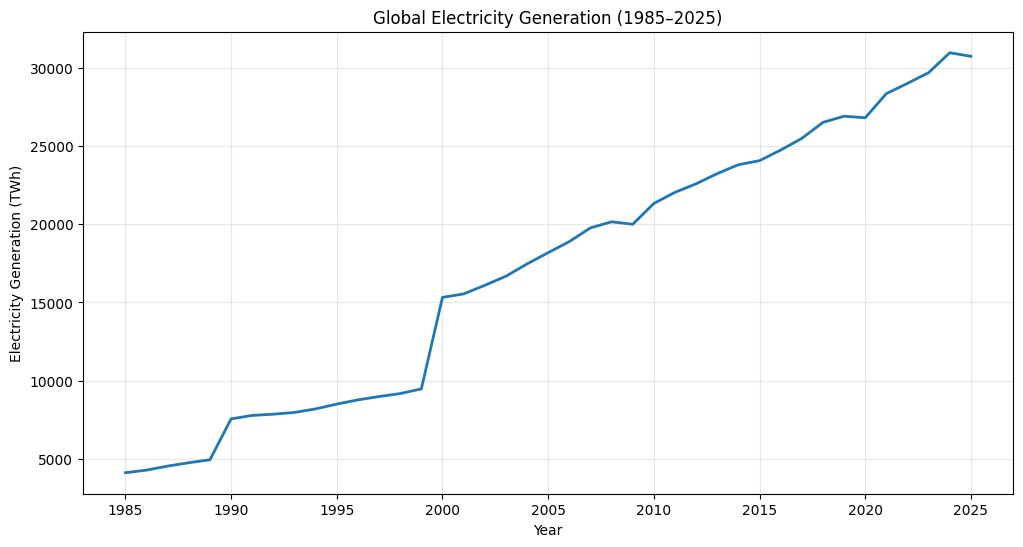

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(
    global_generation["Year"],
    global_generation["total_generation_twh"],
    linewidth=2
)

plt.title("Global Electricity Generation (1985–2025)")
plt.xlabel("Year")
plt.ylabel("Electricity Generation (TWh)")
plt.grid(alpha=0.3)

plt.show()

what is driving that increase: renewable energy or fossil fuels?

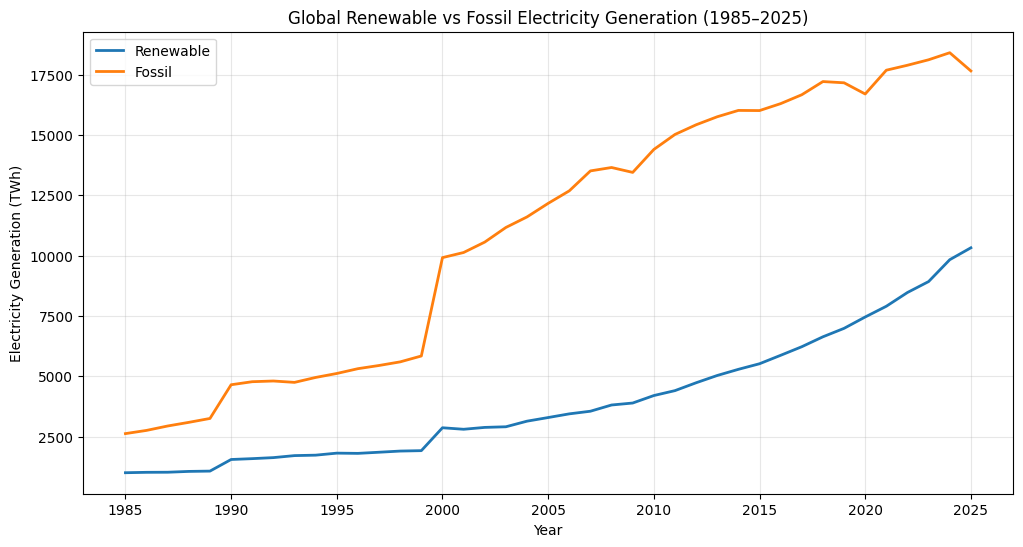

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    global_generation["Year"],
    global_generation["renewable_generation_twh"],
    label="Renewable",
    linewidth=2
)

plt.plot(
    global_generation["Year"],
    global_generation["fossil_generation_twh"],
    label="Fossil",
    linewidth=2
)

plt.title("Global Renewable vs Fossil Electricity Generation (1985–2025)")
plt.xlabel("Year")
plt.ylabel("Electricity Generation (TWh)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
comparison = global_generation[
    global_generation["Year"].isin([1985, 2000, 2010, 2020, 2025])
].copy()

display(comparison.round(2))

,Year,total_generation_twh,renewable_generation_twh,fossil_generation_twh
0,1985,4122.54,1004.54,2625.05
15,2000,15324.46,2867.48,9916.51
25,2010,21326.10,4202.01,14397.88
35,2020,26801.65,7456.84,16696.02
40,2025,30727.77,10324.32,17651.42


calculate the generation shares

In [ ]:
global_generation["renewable_share_pct"] = (
    global_generation["renewable_generation_twh"] /
    global_generation["total_generation_twh"]
) * 100

global_generation["fossil_share_pct"] = (
    global_generation["fossil_generation_twh"] /
    global_generation["total_generation_twh"]
) * 100

display(
    global_generation[
        global_generation["Year"].isin([1985, 2000, 2010, 2020, 2025])
    ][
        [
            "Year",
            "renewable_share_pct",
            "fossil_share_pct"
        ]
    ].round(2)
)

,Year,renewable_share_pct,fossil_share_pct
0,1985,24.37,63.68
15,2000,18.71,64.71
25,2010,19.70,67.51
35,2020,27.82,62.29
40,2025,33.60,57.44


visualize the electricity mix over time

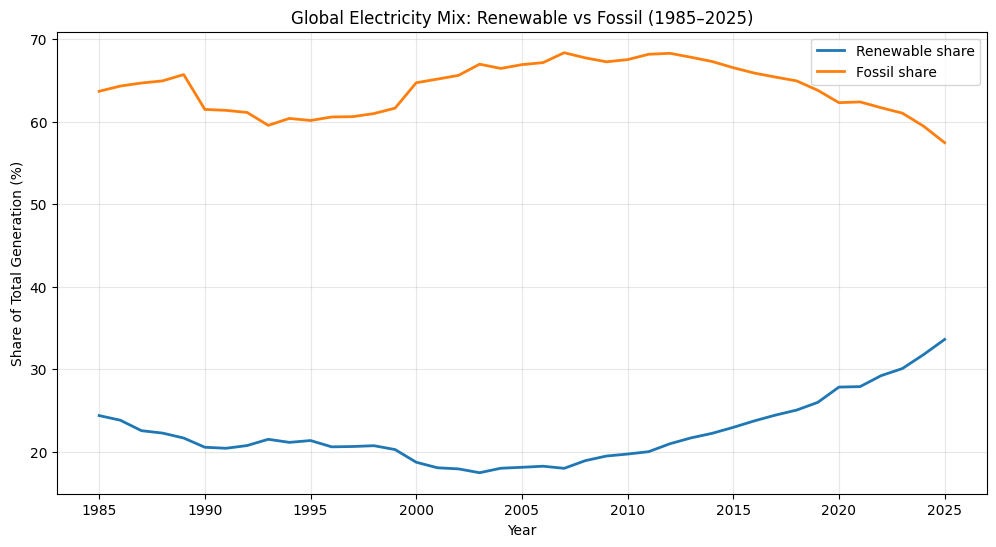

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    global_generation["Year"],
    global_generation["renewable_share_pct"],
    label="Renewable share",
    linewidth=2
)

plt.plot(
    global_generation["Year"],
    global_generation["fossil_share_pct"],
    label="Fossil share",
    linewidth=2
)

plt.title("Global Electricity Mix: Renewable vs Fossil (1985–2025)")
plt.xlabel("Year")
plt.ylabel("Share of Total Generation (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
display(
    global_generation[
        global_generation["Year"].isin([1985, 1990, 2000, 2010, 2020, 2025])
    ][
        ["Year", "renewable_share_pct", "fossil_share_pct"]
    ].round(2)
)

,Year,renewable_share_pct,fossil_share_pct
0,1985,24.37,63.68
5,1990,20.53,61.48
15,2000,18.71,64.71
25,2010,19.70,67.51
35,2020,27.82,62.29
40,2025,33.60,57.44


Prepare the 2025 country dataset

In [ ]:
country_2025 = analysis_df[
    analysis_df["Year"] == 2025
].copy()

print("Number of countries in 2025:", country_2025["Area"].nunique())

display(
    country_2025[
        [
            "Area",
            "total_generation_twh",
            "renewable_generation_twh",
            "renewable_share_pct",
            "fossil_generation_twh",
            "fossil_share_pct",
            "emissions_intensity"
        ]
    ].head(10)
)

Number of countries in 2025: 93


,Area,total_generation_twh,renewable_generation_twh,renewable_share_pct,fossil_generation_twh,fossil_share_pct,emissions_intensity
190,Argentina,153.349,51.884,33.834,90.705,59.149,345.610
216,Armenia,8.504,2.466,28.998,3.378,39.722,244.003
282,Australia,285.922,113.690,39.763,172.232,60.237,517.956
318,Austria,73.239,61.264,83.649,11.975,16.351,116.605
344,Azerbaijan,27.759,3.062,11.030,24.698,88.971,639.324
420,Bangladesh,103.391,2.212,2.139,101.179,97.861,696.095
471,Belarus,45.429,1.257,2.767,27.196,59.864,315.173
507,Belgium,72.080,27.803,38.572,20.131,27.929,151.262
608,Bolivia,13.620,4.918,36.108,8.703,63.897,481.278
634,Bosnia Herzegovina,14.535,6.297,43.323,8.238,56.676,572.755


In [ ]:
top_fossil_countries = (
    country_2025[
        country_2025["fossil_share_pct"].notna()
    ]
    .sort_values(
        "fossil_share_pct",
        ascending=False
    )
    [["Area", "total_generation_twh", "fossil_generation_twh",
      "fossil_share_pct", "renewable_share_pct"]]
    .head(10)
)

display(top_fossil_countries.round(2))

,Area,total_generation_twh,fossil_generation_twh,fossil_share_pct,renewable_share_pct
420,Bangladesh,103.39,101.18,97.86,2.14
2893,Kuwait,89.53,87.43,97.66,2.34
5392,Tunisia,22.38,21.52,96.16,3.84
4595,Saudi Arabia,471.42,451.66,95.81,4.19
4004,Oman,53.05,50.29,94.80,5.20
2535,Iran,398.68,377.92,94.79,3.85
4732,Singapore,60.11,56.82,94.52,5.48
4255,Puerto Rico,19.54,18.40,94.14,5.86
3521,Mongolia,9.75,8.91,91.39,8.62
2867,Kosovo,5.86,5.24,89.45,10.54


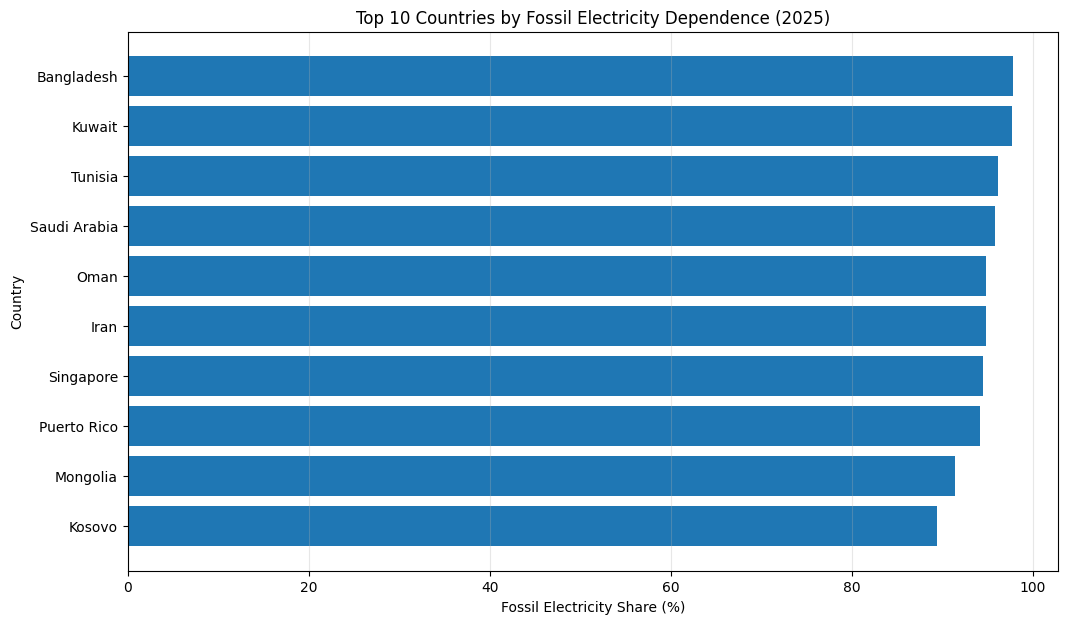

In [ ]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_fossil_countries["Area"],
    top_fossil_countries["fossil_share_pct"]
)

plt.xlabel("Fossil Electricity Share (%)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Fossil Electricity Dependence (2025)")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

In [ ]:
top_renewable_countries = (
    country_2025[
        (country_2025["total_generation_twh"] >= 10) &
        (country_2025["renewable_share_pct"].notna())
    ]
    .sort_values("renewable_share_pct", ascending=False)
    [[
        "Area",
        "total_generation_twh",
        "renewable_generation_twh",
        "renewable_share_pct",
        "fossil_share_pct",
        "emissions_intensity"
    ]]
    .head(10)
)

display(top_renewable_countries.round(2))

,Area,total_generation_twh,renewable_generation_twh,renewable_share_pct,fossil_share_pct,emissions_intensity
2427,Iceland,18.27,18.27,100.00,0.00,27.76
1719,Ethiopia,33.37,33.37,100.00,0.00,23.40
4131,Paraguay,45.35,45.35,100.00,0.00,24.78
1220,Costa Rica,12.94,12.93,99.99,0.01,24.58
3978,Norway,160.85,159.24,99.00,1.00,28.05
5675,Uruguay,12.02,11.74,97.73,2.28,80.55
5199,Tajikistan,24.02,22.67,94.39,5.62,72.64
2919,Kyrgyzstan,12.85,12.01,93.47,6.53,79.85
1414,Denmark,35.61,32.46,91.15,8.85,119.65
2816,Kenya,14.05,12.65,90.05,9.95,95.89


Compare renewable adoption with emissions intensity

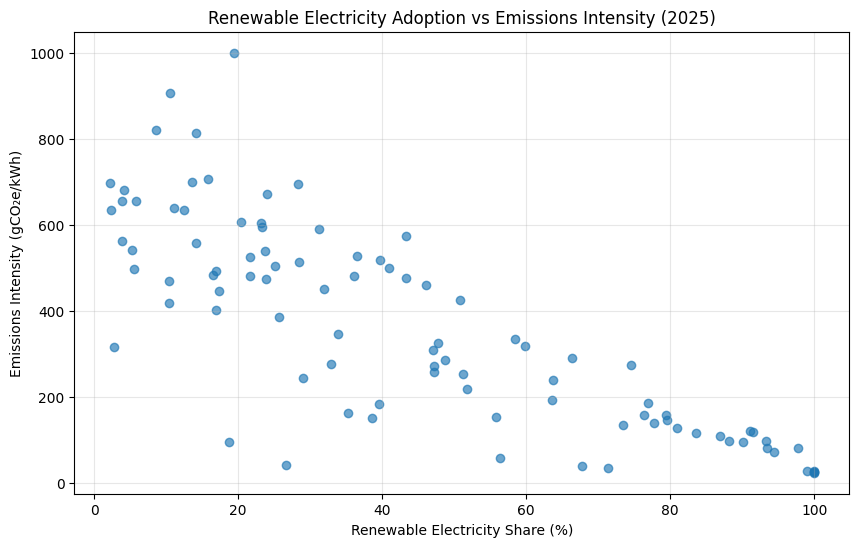

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    country_2025["renewable_share_pct"],
    country_2025["emissions_intensity"],
    alpha=0.65
)

plt.xlabel("Renewable Electricity Share (%)")
plt.ylabel("Emissions Intensity (gCO₂e/kWh)")
plt.title("Renewable Electricity Adoption vs Emissions Intensity (2025)")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
correlation = country_2025[
    ["renewable_share_pct", "emissions_intensity"]
].dropna().corr()

print("Correlation matrix:")
display(correlation.round(3))

print(
    "Number of countries included:",
    country_2025[
        ["renewable_share_pct", "emissions_intensity"]
    ].dropna().shape[0]
)

Correlation matrix:


,renewable_share_pct,emissions_intensity
renewable_share_pct,1.000,-0.809
emissions_intensity,-0.809,1.000


Number of countries included: 93


Regional comparison

In [ ]:
regional_2025 = (
    country_2025
    .groupby("Continent", as_index=False)
    .agg(
        total_generation_twh=("total_generation_twh", "sum"),
        renewable_generation_twh=("renewable_generation_twh", "sum"),
        fossil_generation_twh=("fossil_generation_twh", "sum"),
        total_emissions_mtco2e=("emissions_mtco2e", "sum")
    )
)

regional_2025["renewable_share_pct"] = (
    regional_2025["renewable_generation_twh"] /
    regional_2025["total_generation_twh"] * 100
)

regional_2025["fossil_share_pct"] = (
    regional_2025["fossil_generation_twh"] /
    regional_2025["total_generation_twh"] * 100
)

display(regional_2025.round(2))

,Continent,total_generation_twh,renewable_generation_twh,fossil_generation_twh,total_emissions_mtco2e,renewable_share_pct,fossil_share_pct
0,Africa,641.56,137.84,493.51,365.28,21.49,76.92
1,Asia,18214.13,5432.12,11889.88,10054.12,29.82,65.28
2,Europe,4646.76,1940.19,1763.15,1254.42,41.75,37.94
3,North America,5631.38,1688.55,3063.12,2077.50,29.98,54.39
4,Oceania,329.91,152.47,177.44,152.34,46.22,53.78
5,South America,1264.03,973.14,264.34,207.79,76.99,20.91


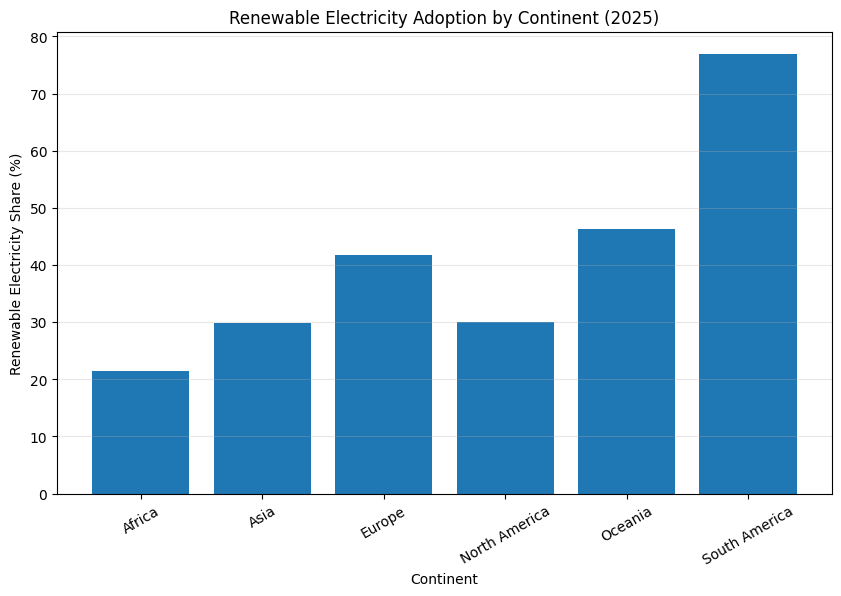

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    regional_2025["Continent"],
    regional_2025["renewable_share_pct"]
)

plt.xlabel("Continent")
plt.ylabel("Renewable Electricity Share (%)")
plt.title("Renewable Electricity Adoption by Continent (2025)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

Regional fossil electricity dependence

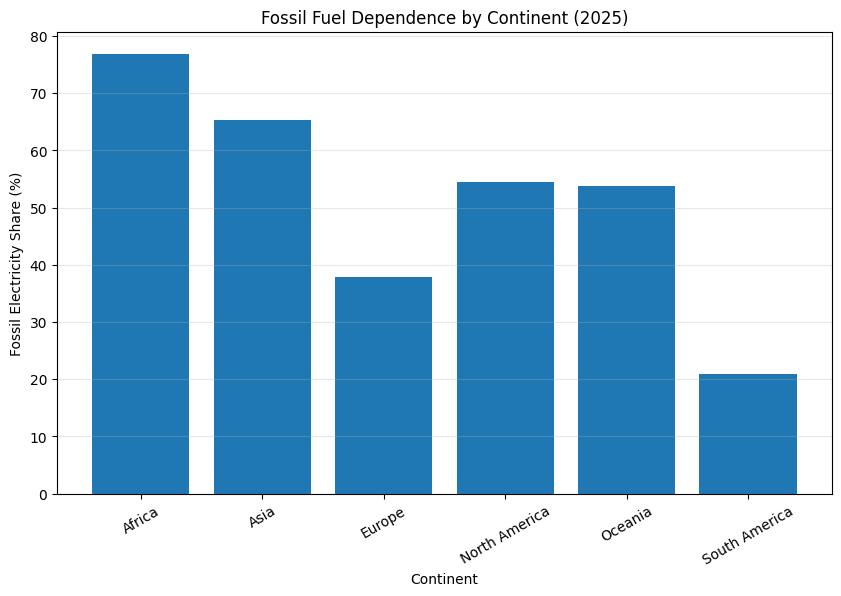

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    regional_2025["Continent"],
    regional_2025["fossil_share_pct"]
)

plt.xlabel("Continent")
plt.ylabel("Fossil Electricity Share (%)")
plt.title("Fossil Fuel Dependence by Continent (2025)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

Bangladesh vs ASEAN countries (2025)

In [ ]:
bangladesh_asean = country_2025[
    (country_2025["Area"] == "Bangladesh") |
    (country_2025["Area"].isin(
        ember_country.loc[
            ember_country["ASEAN member"] == True, "Area"
        ].unique()
    ))
].copy()

display(
    bangladesh_asean[
        [
            "Area",
            "total_generation_twh",
            "renewable_share_pct",
            "fossil_share_pct",
            "emissions_intensity"
        ]
    ].sort_values("renewable_share_pct", ascending=False).round(2)
)

,Area,total_generation_twh,renewable_share_pct,fossil_share_pct,emissions_intensity
5791,Viet Nam,329.04,46.05,53.95,458.94
862,Cambodia,17.76,40.88,59.12,498.76
5291,The Philippines,123.16,23.31,76.69,595.40
5265,Thailand,200.50,21.67,78.33,525.88
3268,Malaysia,210.37,20.41,79.59,605.55
2494,Indonesia,528.21,15.81,84.19,705.33
4732,Singapore,60.11,5.48,94.52,497.05
420,Bangladesh,103.39,2.14,97.86,696.10


Key findings
1. Vietnam leads this comparison, with 46.05% renewable electricity.
2. Cambodia follows with 40.88%.
3. Bangladesh has the lowest renewable share among the eight countries shown.
4. Bangladesh's fossil dependence is 97.86%, considerably higher than every country in this comparison.
5. Bangladesh's emissions intensity is 696.10 gCO₂e/kWh, compared with Vietnam's 458.94.

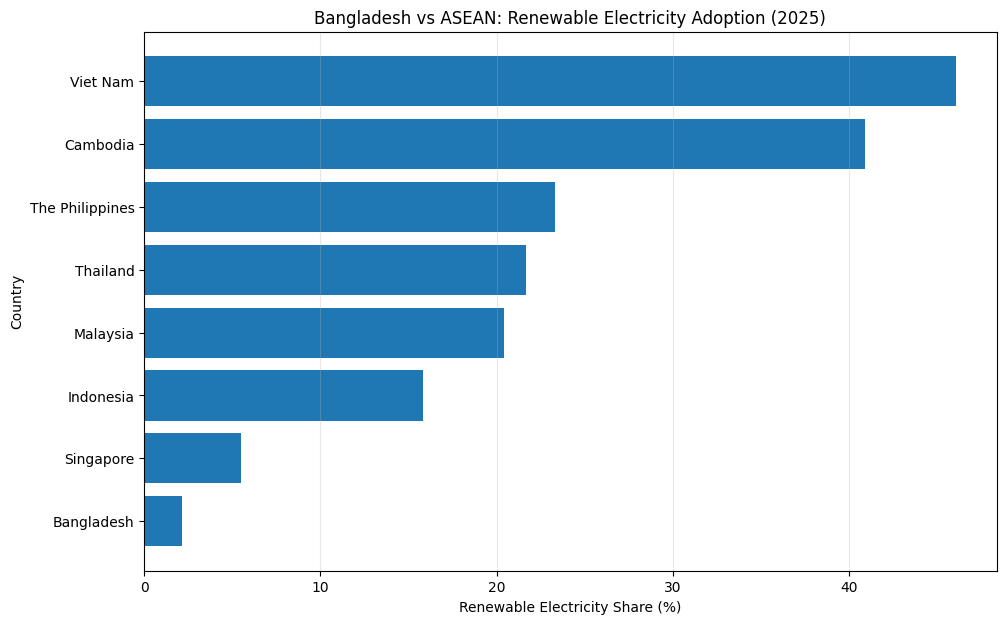

In [ ]:
plt.figure(figsize=(11, 7))

comparison = bangladesh_asean.sort_values(
    "renewable_share_pct", ascending=True
)

plt.barh(
    comparison["Area"],
    comparison["renewable_share_pct"]
)

plt.xlabel("Renewable Electricity Share (%)")
plt.ylabel("Country")
plt.title("Bangladesh vs ASEAN: Renewable Electricity Adoption (2025)")
plt.grid(axis="x", alpha=0.3)
plt.show()

Electricity emissions intensity: Bangladesh vs ASEAN.

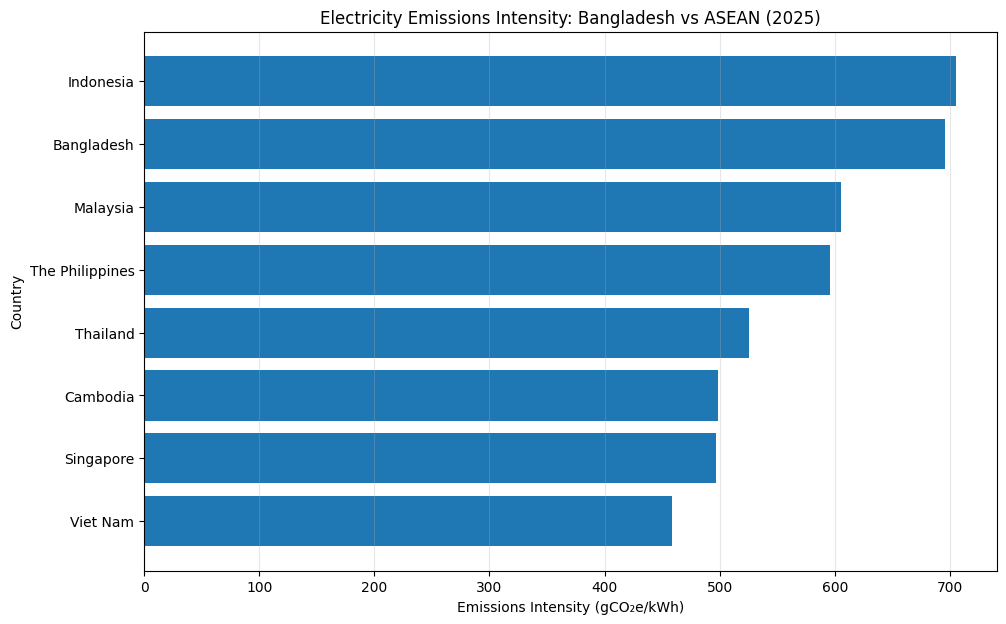

In [ ]:
plt.figure(figsize=(11, 7))

comparison = bangladesh_asean.sort_values(
    "emissions_intensity", ascending=True
)

plt.barh(
    comparison["Area"],
    comparison["emissions_intensity"]
)

plt.xlabel("Emissions Intensity (gCO₂e/kWh)")
plt.ylabel("Country")
plt.title("Electricity Emissions Intensity: Bangladesh vs ASEAN (2025)")
plt.grid(axis="x", alpha=0.3)
plt.show()

Bangladesh's electricity transition over time (1985–2025).

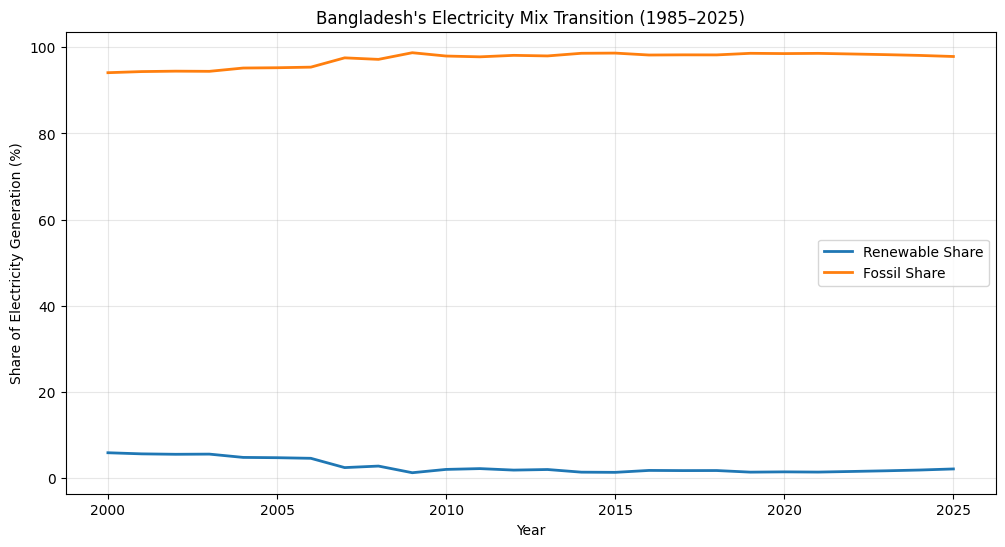

In [ ]:
bangladesh_trend = analysis_df[
    analysis_df["Area"] == "Bangladesh"
].sort_values("Year").copy()

plt.figure(figsize=(12, 6))

plt.plot(
    bangladesh_trend["Year"],
    bangladesh_trend["renewable_share_pct"],
    label="Renewable Share",
    linewidth=2
)

plt.plot(
    bangladesh_trend["Year"],
    bangladesh_trend["fossil_share_pct"],
    label="Fossil Share",
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Share of Electricity Generation (%)")
plt.title("Bangladesh's Electricity Mix Transition (1985–2025)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Bangladesh's emissions intensity trend

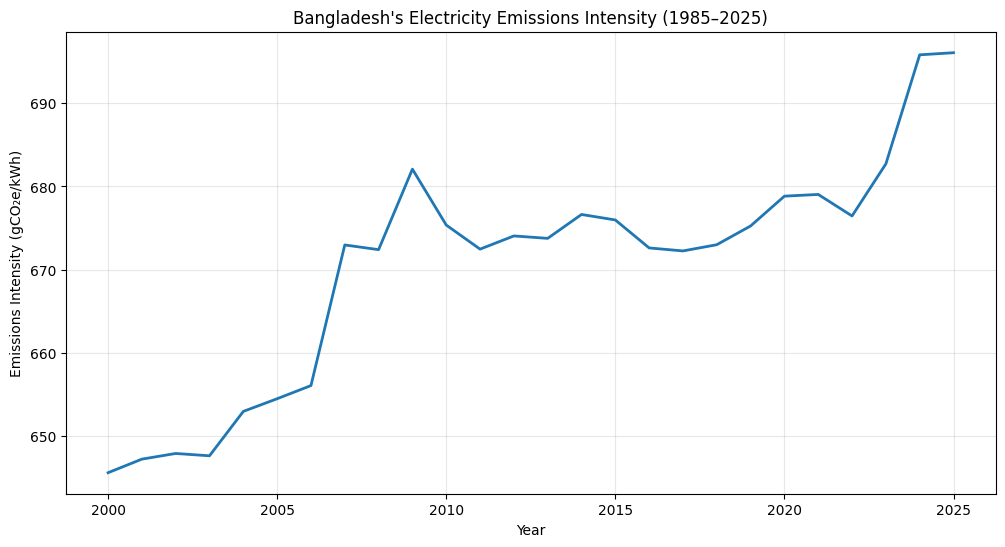

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    bangladesh_trend["Year"],
    bangladesh_trend["emissions_intensity"],
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Emissions Intensity (gCO₂e/kWh)")
plt.title("Bangladesh's Electricity Emissions Intensity (1985–2025)")
plt.grid(alpha=0.3)
plt.show()

Measure Bangladesh's historical change

In [ ]:
bd_selected = bangladesh_trend[
    bangladesh_trend["Year"].isin([1985, 2000, 2010, 2020, 2025])
][
    [
        "Year",
        "total_generation_twh",
        "renewable_share_pct",
        "fossil_share_pct",
        "emissions_mtco2e",
        "emissions_intensity"
    ]
].sort_values("Year")

display(bd_selected.round(2))

,Year,total_generation_twh,renewable_share_pct,fossil_share_pct,emissions_mtco2e,emissions_intensity
395,2000,15.94,5.90,94.10,10.29,645.55
405,2010,40.86,2.03,97.97,27.60,675.36
415,2020,85.46,1.46,98.54,58.01,678.83
420,2025,103.39,2.14,97.86,71.97,696.10


Bangladesh's electricity generation expanded dramatically between 2000 and 2025.



Renewable electricity adoption did not keep pace with this expansion. Its share actually declined.



Both total emissions and emissions intensity increased.

Identify the biggest electricity transitions globally

In [ ]:
transition_df = analysis_df[
    analysis_df["Year"].isin([2000, 2025])
].pivot(
    index="Area",
    columns="Year",
    values="renewable_share_pct"
).reset_index()

transition_df = transition_df.dropna(
    subset=[2000, 2025]
)

transition_df["renewable_share_change_pp"] = (
    transition_df[2025] - transition_df[2000]
)

top_transitions = transition_df.sort_values(
    "renewable_share_change_pp",
    ascending=False
).head(10)

display(top_transitions.round(2))

Year,Area,2000,2025,renewable_share_change_pp
49,Denmark,15.54,91.15,75.62
109,Lithuania,3.06,77.70,74.65
58,Estonia,0.12,59.80,59.68
71,Germany,6.22,58.46,52.24
110,Luxembourg,40.00,91.48,51.48
149,Portugal,29.78,80.88,51.10
98,Kenya,40.37,90.05,49.68
196,United Kingdom,2.63,51.82,49.20
132,Netherlands,3.37,51.20,47.83
91,Ireland,5.04,47.20,42.16


What we can conclude
- Denmark achieved the largest increase among the countries in your comparison.
- Several European countries made substantial progress.
- Kenya is an interesting non-European example, reaching 90.05% renewable electricity.
- Bangladesh's renewable share declined by 3.76 percentage points over the same period.

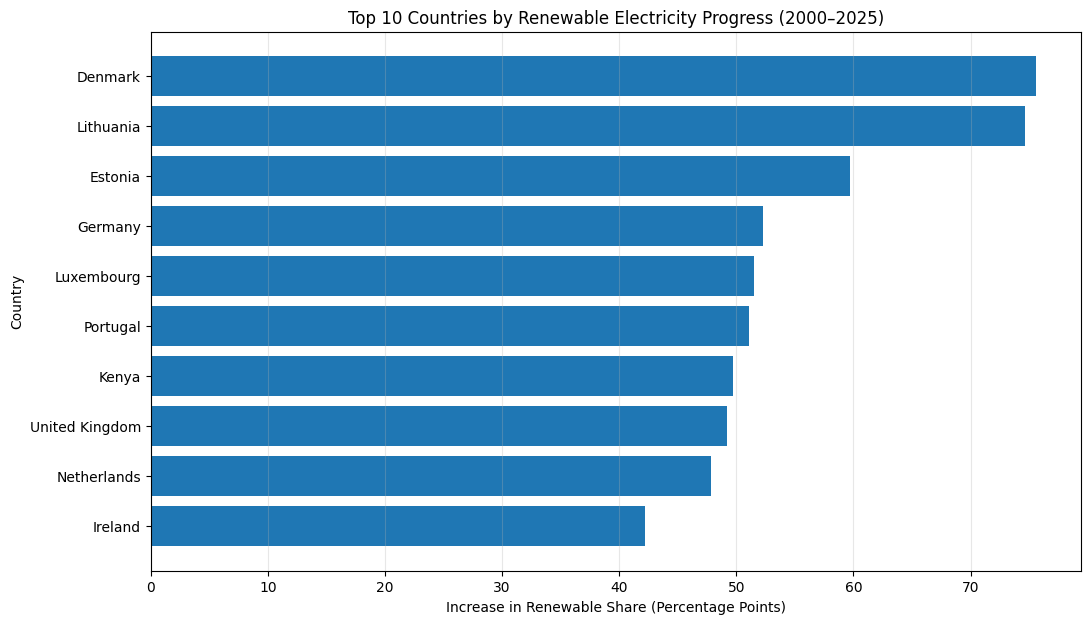

In [ ]:
plt.figure(figsize=(12, 7))

plot_data = top_transitions.sort_values(
    "renewable_share_change_pp"
)

plt.barh(
    plot_data["Area"],
    plot_data["renewable_share_change_pp"]
)

plt.xlabel("Increase in Renewable Share (Percentage Points)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Renewable Electricity Progress (2000–2025)")
plt.grid(axis="x", alpha=0.3)
plt.show()

Validate the historical comparison

In [ ]:
print("Countries with data in both years:",
      len(transition_df))

print("\nBangladesh's renewable transition:")

display(
    transition_df[
        transition_df["Area"] == "Bangladesh"
    ].round(2)
)

Countries with data in both years: 92

Bangladesh's renewable transition:


Year,Area,2000,2025,renewable_share_change_pp
14,Bangladesh,5.9,2.14,-3.76


In [ ]:
bottom_transitions = transition_df.sort_values(
    "renewable_share_change_pp",
    ascending=True
).head(10)

display(bottom_transitions.round(2))

Year,Area,2000,2025,renewable_share_change_pp
185,The Philippines,42.89,23.31,-19.58
147,Peru,81.98,63.66,-18.31
21,Bolivia,51.55,36.11,-15.44
202,Viet Nam,54.78,46.05,-8.74
137,Nigeria,38.26,31.98,-6.28
22,Bosnia Herzegovina,48.80,43.32,-5.48
54,Egypt,19.45,14.07,-5.38
182,Tajikistan,98.46,94.39,-4.07
14,Bangladesh,5.90,2.14,-3.76
88,Indonesia,19.02,15.81,-3.21


In [ ]:
balanced_countries = transition_df["Area"].tolist()

balanced_global = analysis_df[
    (analysis_df["Area"].isin(balanced_countries)) &
    (analysis_df["Year"].isin([2000, 2025]))
].copy()

global_balanced = (
    balanced_global.groupby("Year", as_index=False)
    .agg(
        total_generation_twh=("total_generation_twh", "sum"),
        renewable_generation_twh=("renewable_generation_twh", "sum"),
        fossil_generation_twh=("fossil_generation_twh", "sum")
    )
)

global_balanced["renewable_share_pct"] = (
    global_balanced["renewable_generation_twh"] /
    global_balanced["total_generation_twh"] * 100
)

global_balanced["fossil_share_pct"] = (
    global_balanced["fossil_generation_twh"] /
    global_balanced["total_generation_twh"] * 100
)

display(global_balanced.round(2))

,Year,total_generation_twh,renewable_generation_twh,fossil_generation_twh,renewable_share_pct,fossil_share_pct
0,2000,14701.98,2695.70,9543.15,18.34,64.91
1,2025,30725.34,10322.51,17650.81,33.60,57.45


Key findings
1. Total electricity generation more than doubled.
2. Renewable generation increased by approximately 283%.
3. Renewable share increased by 15.26 percentage points.
4. Fossil generation also increased, despite its declining share.
5. Fossil electricity share declined by 7.46 percentage points.

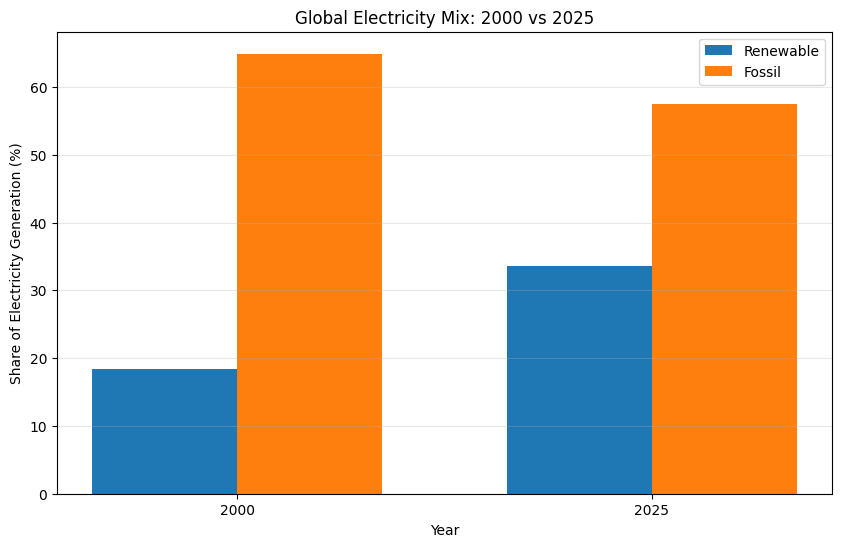

In [ ]:
plt.figure(figsize=(10, 6))

years = global_balanced["Year"].astype(str)
x = range(len(years))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    global_balanced["renewable_share_pct"],
    width,
    label="Renewable"
)

plt.bar(
    [i + width/2 for i in x],
    global_balanced["fossil_share_pct"],
    width,
    label="Fossil"
)

plt.xticks(list(x), years)
plt.ylabel("Share of Electricity Generation (%)")
plt.xlabel("Year")
plt.title("Global Electricity Mix: 2000 vs 2025")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

Validate country and year coverage

In [ ]:
coverage_check = (
    analysis_df[analysis_df["Year"].isin([2000, 2025])]
    .groupby("Year")
    .agg(
        country_count=("Area", "nunique"),
        total_generation_missing=("total_generation_twh", lambda x: x.isna().sum()),
        renewable_generation_missing=("renewable_generation_twh", lambda x: x.isna().sum()),
        emissions_intensity_missing=("emissions_intensity", lambda x: x.isna().sum())
    )
)

print("Country coverage by year:")
display(coverage_check)

print("Countries with comparable renewable-share data:",
      len(transition_df))

print("Duplicate country-year records:",
      analysis_df.duplicated(["Area", "Year"]).sum())

Country coverage by year:


,country_count,total_generation_missing,renewable_generation_missing,emissions_intensity_missing
Year,,,,
2000,207,0,1,0
2025,93,0,0,0


Countries with comparable renewable-share data: 92
Duplicate country-year records: 0


In [ ]:
share_validation = analysis_df.copy()

share_validation["renewable_share_difference"] = (
    share_validation["renewable_share_pct"] -
    share_validation["renewable_generation_twh"].div(
        share_validation["total_generation_twh"]
    ) * 100
)

share_validation["fossil_share_difference"] = (
    share_validation["fossil_share_pct"] -
    share_validation["fossil_generation_twh"].div(
        share_validation["total_generation_twh"]
    ) * 100
)

print("Renewable share difference:")
display(
    share_validation["renewable_share_difference"]
    .abs().describe().round(6)
)

print("Fossil share difference:")
display(
    share_validation["fossil_share_difference"]
    .abs().describe().round(6)
)

Renewable share difference:


,renewable_share_difference
count,5906.000000
mean,0.000212
std,0.000320
min,0.000000
25%,0.000026
50%,0.000189
75%,0.000344
max,0.015696


Fossil share difference:


,fossil_share_difference
count,5913.000000
mean,0.000214
std,0.000299
min,0.000000
25%,0.000025
50%,0.000194
75%,0.000346
max,0.011645


In [ ]:
generation_validation = analysis_df.copy()

generation_validation["generation_difference_twh"] = (
    generation_validation["total_generation_twh"] -
    generation_validation["renewable_generation_twh"] -
    generation_validation["fossil_generation_twh"]
)

print("Generation difference summary:")
display(
    generation_validation["generation_difference_twh"]
    .describe()
    .round(3)
)

print(
    "Records where renewable + fossil exceeds total:",
    (generation_validation["generation_difference_twh"] < -0.01).sum()
)

print(
    "Records where generation difference is negative:",
    (generation_validation["generation_difference_twh"] < 0).sum()
)

Generation difference summary:


,generation_difference_twh
count,5908.000
mean,14.733
std,68.474
min,-0.001
25%,0.000
50%,0.000
75%,0.000
max,809.410


Records where renewable + fossil exceeds total: 0
Records where generation difference is negative: 896


In [ ]:
generation_validation = analysis_df.copy()

generation_validation["generation_difference_twh"] = (
    generation_validation["total_generation_twh"] -
    generation_validation["renewable_generation_twh"] -
    generation_validation["fossil_generation_twh"]
)

negative_records = generation_validation[
    generation_validation["generation_difference_twh"] < 0
][
    [
        "Area",
        "Year",
        "total_generation_twh",
        "renewable_generation_twh",
        "fossil_generation_twh",
        "generation_difference_twh"
    ]
]

display(negative_records.head(15).round(4))

,Area,Year,total_generation_twh,renewable_generation_twh,fossil_generation_twh,generation_difference_twh
0,Afghanistan,2000,0.48,0.31,0.17,-0.0
1,Afghanistan,2001,0.69,0.50,0.19,-0.0
2,Afghanistan,2002,0.71,0.56,0.15,-0.0
4,Afghanistan,2004,0.79,0.56,0.23,-0.0
5,Afghanistan,2005,0.82,0.59,0.23,-0.0
9,Afghanistan,2009,0.89,0.78,0.11,-0.0
14,Afghanistan,2014,1.16,1.00,0.16,-0.0
15,Afghanistan,2015,1.18,1.03,0.15,-0.0
16,Afghanistan,2016,1.21,1.06,0.15,-0.0
17,Afghanistan,2017,1.26,1.09,0.17,-0.0


In [ ]:
negative_records["absolute_difference"] = (
    negative_records["generation_difference_twh"].abs()
)

print("Largest discrepancy (TWh):")
print(negative_records["absolute_difference"].max())

print("\nDiscrepancy distribution:")
display(
    negative_records["absolute_difference"]
    .describe()
    .round(8)
)

Largest discrepancy (TWh):
0.0010000000000331966

Discrepancy distribution:


,absolute_difference
count,896.000000
mean,0.000033
std,0.000180
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.001000


Check historical country coverage

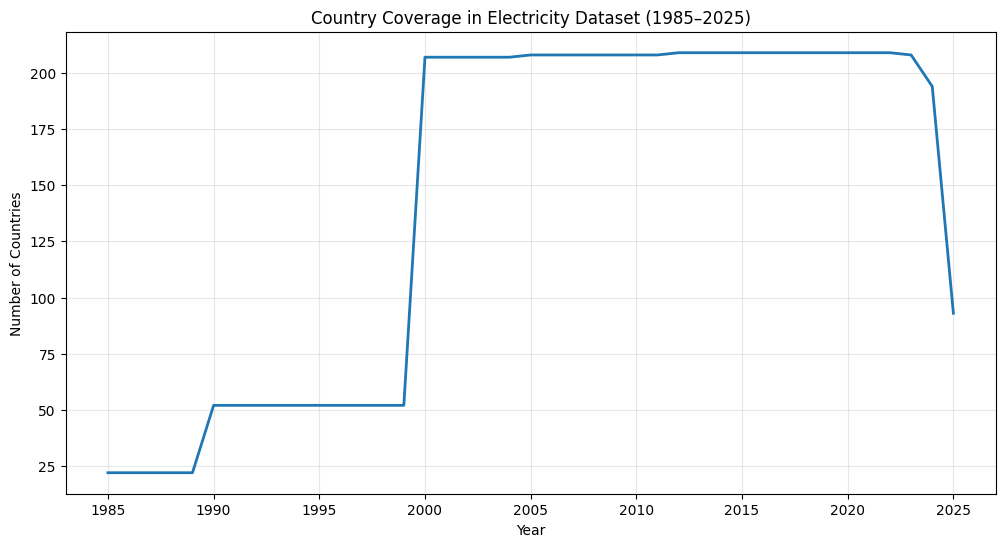

,Year,country_count,total_generation_twh
0,1985,22,4122.54
5,1990,52,7562.96
15,2000,207,15324.46
25,2010,208,21326.10
35,2020,209,26801.65
40,2025,93,30727.77


In [ ]:
yearly_coverage = (
    analysis_df.groupby("Year")
    .agg(
        country_count=("Area", "nunique"),
        total_generation_twh=("total_generation_twh", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_coverage["Year"],
    yearly_coverage["country_count"],
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Number of Countries")
plt.title("Country Coverage in Electricity Dataset (1985–2025)")
plt.grid(alpha=0.3)
plt.show()

display(
    yearly_coverage[
        yearly_coverage["Year"].isin([1985, 1990, 2000, 2010, 2020, 2025])
    ].round(2)
)

Identify countries missing from 2025

In [ ]:
countries_2020 = set(
    analysis_df.loc[
        analysis_df["Year"] == 2020, "Area"
    ]
)

countries_2025 = set(
    analysis_df.loc[
        analysis_df["Year"] == 2025, "Area"
    ]
)

missing_2025 = sorted(countries_2020 - countries_2025)

print("Countries in 2020:", len(countries_2020))
print("Countries in 2025:", len(countries_2025))
print("Countries missing in 2025:", len(missing_2025))

print("\nMissing countries:")
print(missing_2025)

Countries in 2020: 209
Countries in 2025: 93
Countries missing in 2025: 116

Missing countries:
['Afghanistan', 'Albania', 'Algeria', 'American Samoa', 'Angola', 'Antigua and Barbuda', 'Aruba', 'Bahamas', 'Bahrain', 'Barbados', 'Belize', 'Benin', 'Bhutan', 'Botswana', 'Brunei Darussalam', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cameroon', 'Cayman Islands', 'Central African Republic', 'Chad', 'Comoros', 'Congo', 'Congo (DRC)', 'Cook Islands (the)', "Cote d'Ivoire", 'Cuba', 'Djibouti', 'Dominica', 'Equatorial Guinea', 'Eritrea', 'Eswatini', 'Falkland Islands (Malvinas)', 'Faroe Islands', 'Fiji', 'French Guiana', 'French Polynesia', 'Gabon', 'Gambia', 'Ghana', 'Greenland', 'Grenada', 'Guadeloupe', 'Guam', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hong Kong (SAR of China)', 'Iraq', 'Jamaica', 'Jordan', 'Kiribati', 'Lao PDR', 'Lebanon', 'Lesotho', 'Liberia', 'Libya', 'Macao (SAR of China)', 'Madagascar', 'Malawi', 'Maldives', 'Mali', 'Martinique', 'Mauritania

In [ ]:
missing_country_2025 = ember_country[
    (ember_country["Area"].isin(missing_2025)) &
    (ember_country["Year"] == 2025)
]

print("2025 records for missing countries:",
      len(missing_country_2025))

print("\nCountry-level records by source:")
display(
    missing_country_2025.groupby(
        "Electricity source"
    ).size().sort_values(ascending=False)
)

2025 records for missing countries: 0

Country-level records by source:


,0
Electricity source,


In [ ]:
display(
    yearly_coverage[
        yearly_coverage["Year"] >= 2015
    ][
        ["Year", "country_count"]
    ].to_string(index=False)
)

' Year  country_count\n 2015            209\n 2016            209\n 2017            209\n 2018            209\n 2019            209\n 2020            209\n 2021            209\n 2022            209\n 2023            208\n 2024            194\n 2025             93'

In [ ]:
world_2025 = ember[
    (ember["Area"] == "World") &
    (ember["Year"] == 2025) &
    (ember["Electricity source"].isin([
        "Total generation",
        "Renewables",
        "Fossil"
    ]))
]

display(
    world_2025[
        [
            "Area",
            "Year",
            "Electricity source",
            "Generation (TWh)",
            "Share of generation (%)",
            "Emissions (MtCO2e)"
        ]
    ]
)

,Area,Year,Electricity source,Generation (TWh),Share of generation (%),Emissions (MtCO2e)
102961,World,2025,Renewables,10702.182,33.523,416.365
102963,World,2025,Fossil,18417.278,57.690,14257.618
102964,World,2025,Total generation,31924.491,100.000,14688.722


Check historical World aggregates

In [ ]:
world_history = ember[
    (ember["Area"] == "World") &
    (ember["Electricity source"].isin([
        "Total generation",
        "Renewables",
        "Fossil"
    ]))
].copy()

world_coverage = (
    world_history.groupby("Year")
    .agg(
        source_count=("Electricity source", "nunique")
    )
    .reset_index()
)

print("World aggregate year coverage:")
display(world_coverage)

print("\nYear range:")
print(
    world_history["Year"].min(),
    "to",
    world_history["Year"].max()
)

World aggregate year coverage:


,Year,source_count
0,2000,3
1,2001,3
2,2002,3
3,2003,3
4,2004,3
5,2005,3
6,2006,3
7,2007,3
8,2008,3
9,2009,3



Year range:
2000 to 2025


In [ ]:
stat_data = analysis_df[
    analysis_df["Year"] == 2024
][[
    "Area",
    "renewable_share_pct",
    "fossil_share_pct",
    "emissions_intensity",
    "total_generation_twh"
]].copy()
print("Number of country records:", len(stat_data))

print("\nMissing values:")
display(stat_data.isnull().sum())

print("\nDescriptive statistics:")
display(stat_data.describe().round(2))

Number of country records: 194

Missing values:


,0
Area,0
renewable_share_pct,1
fossil_share_pct,1
emissions_intensity,1
total_generation_twh,0



Descriptive statistics:


,renewable_share_pct,fossil_share_pct,emissions_intensity,total_generation_twh
count,193.00,193.00,193.00,194.00
mean,39.16,57.20,420.80,159.58
std,31.97,33.16,242.30,806.01
min,0.00,0.00,23.49,0.00
25%,11.24,26.49,203.74,1.70
50%,31.14,64.25,470.79,14.35
75%,63.48,86.67,604.35,59.51
max,100.00,100.00,1306.15,10025.01


In [ ]:
correlation_data = stat_data[
    ["Area", "renewable_share_pct", "emissions_intensity"]
].dropna().copy()

print("Original country records:", len(stat_data))
print("Usable observations:", len(correlation_data))
print("Excluded observations:", len(stat_data) - len(correlation_data))

print("\nMissing values after selection:")
display(correlation_data.isnull().sum())

Original country records: 194
Usable observations: 193
Excluded observations: 1

Missing values after selection:


,0
Area,0
renewable_share_pct,0
emissions_intensity,0


In [ ]:
from scipy.stats import pearsonr, spearmanr
pearson_r, pearson_p = pearsonr(
    correlation_data["renewable_share_pct"],
    correlation_data["emissions_intensity"]
)
spearman_r, spearman_p = spearmanr(
    correlation_data["renewable_share_pct"],
    correlation_data["emissions_intensity"]
)

print("Number of countries:", len(correlation_data))

print("\nPEARSON CORRELATION")
print("Correlation coefficient:", round(pearson_r, 4))
print("P-value:", round(pearson_p, 6))

print("\nSPEARMAN CORRELATION")
print("Correlation coefficient:", round(spearman_r, 4))
print("P-value:", round(spearman_p, 6))

Number of countries: 193

PEARSON CORRELATION
Correlation coefficient: -0.8771
P-value: 0.0

SPEARMAN CORRELATION
Correlation coefficient: -0.8952
P-value: 0.0


In [ ]:
from scipy.stats import pearsonr, spearmanr
fossil_data = stat_data[
    ["Area", "fossil_share_pct", "emissions_intensity"]
].dropna().copy()

fossil_pearson = pearsonr(
    fossil_data["fossil_share_pct"],
    fossil_data["emissions_intensity"]
)


fossil_spearman = spearmanr(
    fossil_data["fossil_share_pct"],
    fossil_data["emissions_intensity"]
)

print("Number of countries:", len(fossil_data))

print("\nPEARSON CORRELATION")
print("Coefficient:", round(fossil_pearson.statistic, 4))
print("P-value:", f"{fossil_pearson.pvalue:.3e}")

print("\nSPEARMAN CORRELATION")
print("Coefficient:", round(fossil_spearman.statistic, 4))
print("P-value:", f"{fossil_spearman.pvalue:.3e}")

Number of countries: 193

PEARSON CORRELATION
Coefficient: 0.9357
P-value: 2.408e-88

SPEARMAN CORRELATION
Coefficient: 0.9474
P-value: 2.016e-96


In [ ]:
from scipy.stats import pearsonr, spearmanr

emissions_data = stat_data[
    ["Area", "renewable_share_pct", "total_generation_twh"]
].copy()


emissions_2024 = analysis_df[
    analysis_df["Year"] == 2024
][["Area", "emissions_mtco2e"]]

emissions_data = emissions_data.merge(
    emissions_2024,
    on="Area",
    how="left",
    validate="one_to_one"
)

emissions_data = emissions_data[
    ["Area", "renewable_share_pct", "emissions_mtco2e"]
].dropna()

pearson_result = pearsonr(
    emissions_data["renewable_share_pct"],
    emissions_data["emissions_mtco2e"]
)

spearman_result = spearmanr(
    emissions_data["renewable_share_pct"],
    emissions_data["emissions_mtco2e"]
)

print("Number of countries:", len(emissions_data))

print("\nPearson correlation:", round(pearson_result.statistic, 4))
print("Pearson p-value:", f"{pearson_result.pvalue:.3e}")

print("\nSpearman correlation:", round(spearman_result.statistic, 4))
print("Spearman p-value:", f"{spearman_result.pvalue:.3e}")

Number of countries: 193

Pearson correlation: -0.0677
Pearson p-value: 3.499e-01

Spearman correlation: -0.1968
Spearman p-value: 6.086e-03


In [ ]:
import numpy as np


renewable_median = correlation_data["renewable_share_pct"].median()
correlation_data["renewable_group"] = np.where(
    correlation_data["renewable_share_pct"] >= renewable_median,
    "High renewable adoption",
    "Low renewable adoption"
)

group_summary = (
    correlation_data.groupby("renewable_group")
    .agg(
        country_count=("Area", "count"),
        average_renewable_share=("renewable_share_pct", "mean"),
        average_emissions_intensity=("emissions_intensity", "mean"),
        median_emissions_intensity=("emissions_intensity", "median")
    )
    .round(2)
)

print("Median renewable share:", round(renewable_median, 2), "%")
display(group_summary)

Median renewable share: 31.14 %


,country_count,average_renewable_share,average_emissions_intensity,median_emissions_intensity
renewable_group,,,,
High renewable adoption,97,65.73,243.26,220.33
Low renewable adoption,96,12.31,600.19,602.61


In [ ]:
from scipy.stats import mannwhitneyu

high_group = correlation_data.loc[
    correlation_data["renewable_group"] == "High renewable adoption",
    "emissions_intensity"
]

low_group = correlation_data.loc[
    correlation_data["renewable_group"] == "Low renewable adoption",
    "emissions_intensity"
]

u_statistic, p_value = mannwhitneyu(
    high_group,
    low_group,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", round(u_statistic, 2))
print("P-value:", f"{p_value:.3e}")

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

Mann-Whitney U statistic: 584.0
P-value: 9.248e-26
Result: Statistically significant difference.


In [ ]:
from scipy.stats import linregress

regression_result = linregress(
    correlation_data["renewable_share_pct"],
    correlation_data["emissions_intensity"]
)

print("SIMPLE LINEAR REGRESSION")
print("------------------------")
print("Slope:", round(regression_result.slope, 4))
print("Intercept:", round(regression_result.intercept, 4))
print("R-squared:", round(regression_result.rvalue**2, 4))
print("P-value:", f"{regression_result.pvalue:.3e}")
print("Standard error:", round(regression_result.stderr, 4))

SIMPLE LINEAR REGRESSION
------------------------
Slope: -6.6465
Intercept: 681.0449
R-squared: 0.7692
P-value: 1.007e-62
Standard error: 0.2634


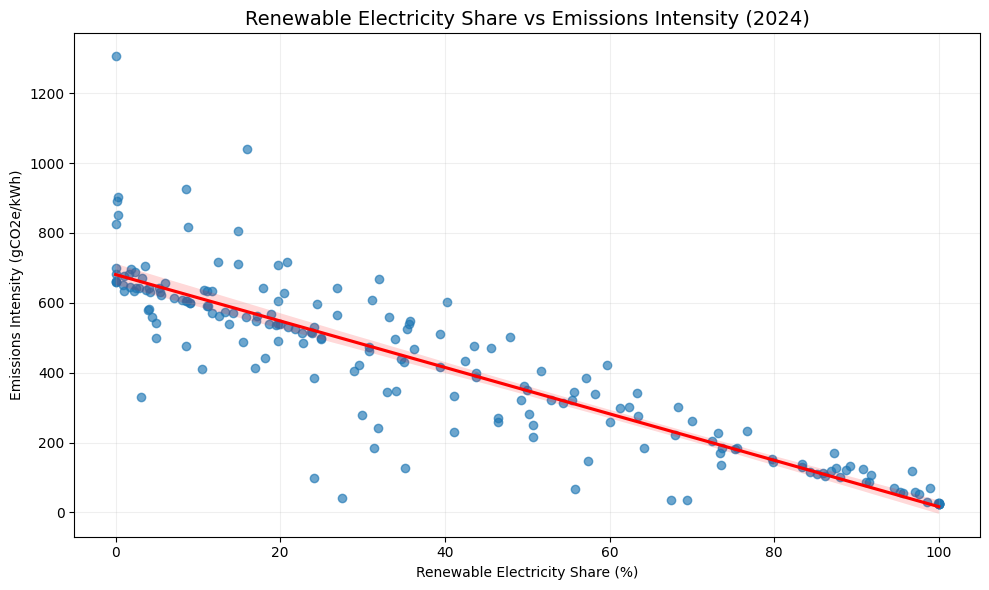

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=correlation_data,
    x="renewable_share_pct",
    y="emissions_intensity",
    scatter_kws={"alpha": 0.65},
    line_kws={"color": "red"}
)

plt.title(
    "Renewable Electricity Share vs Emissions Intensity (2024)",
    fontsize=14
)
plt.xlabel("Renewable Electricity Share (%)")
plt.ylabel("Emissions Intensity (gCO2e/kWh)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

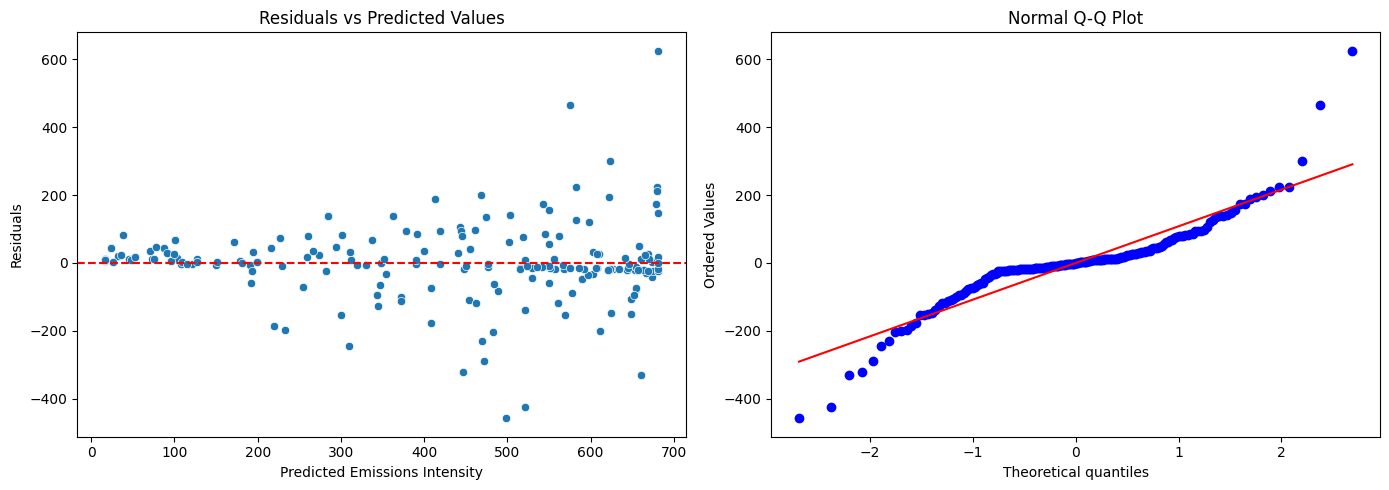

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import probplot

X = correlation_data["renewable_share_pct"]
Y = correlation_data["emissions_intensity"]

predicted = regression_result.intercept + regression_result.slope * X
residuals = Y - predicted


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=predicted, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Values")
axes[0].set_xlabel("Predicted Emissions Intensity")
axes[0].set_ylabel("Residuals")

probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

In [ ]:
import statsmodels.api as sm
X = correlation_data["renewable_share_pct"]
Y = correlation_data["emissions_intensity"]


X = sm.add_constant(X)
robust_model = sm.OLS(Y, X).fit(cov_type="HC3")

print(robust_model.summary())

                             OLS Regression Results                            
Dep. Variable:     emissions_intensity   R-squared:                       0.769
Model:                             OLS   Adj. R-squared:                  0.768
Method:                  Least Squares   F-statistic:                     956.8
Date:                 Wed, 04 Nov 2026   Prob (F-statistic):           2.64e-76
Time:                         20:16:41   Log-Likelihood:                -1191.5
No. Observations:                  193   AIC:                             2387.
Df Residuals:                      191   BIC:                             2393.
Df Model:                            1                                         
Covariance Type:                   HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 68

In [ ]:
influence = robust_model.get_influence()

diagnostics = correlation_data[
    ["Area", "renewable_share_pct", "emissions_intensity"]
].copy()

diagnostics["studentized_residual"] = (
    influence.resid_studentized_external
)

diagnostics["leverage"] = influence.hat_matrix_diag

diagnostics["cooks_distance"] = (
    influence.cooks_distance[0]
)
n = len(diagnostics)
cooks_threshold = 4 / n
leverage_threshold = 4 / n

print("Number of observations:", n)
print("Cook's distance reference:", round(cooks_threshold, 4))
print("Leverage reference:", round(leverage_threshold, 4))

print("\nTop 10 countries by Cook's distance:")

display(
    diagnostics.sort_values(
        "cooks_distance",
        ascending=False
    ).head(10).round(4)
)

Number of observations: 193
Cook's distance reference: 0.0207
Leverage reference: 0.0207

Top 10 countries by Cook's distance:


,Area,renewable_share_pct,emissions_intensity,studentized_residual,leverage,cooks_distance
5417,Turkmenistan,0.030,1306.150,5.8421,0.0130,0.1912
5700,Uzbekistan,15.951,1040.172,4.1696,0.0079,0.0640
470,Belarus,3.077,329.463,-2.9094,0.0118,0.0487
1863,France,27.526,40.337,-4.0928,0.0059,0.0457
4767,Slovakia,24.054,97.185,-3.7683,0.0063,0.0424
2866,Kosovo,8.606,924.900,2.6324,0.0099,0.0337
394,Bahrain,0.264,902.477,1.9387,0.0129,0.0242
725,Brunei Darussalam,0.180,892.986,1.8498,0.0129,0.0221
506,Belgium,35.205,126.931,-2.7990,0.0053,0.0200
2400,Hungary,31.425,183.894,-2.5111,0.0055,0.0169


In [ ]:
full_model = robust_model

sensitivity_data = correlation_data[
    ~correlation_data["Area"].isin(
        ["Turkmenistan", "Uzbekistan"]
    )
].copy()

X_sensitivity = sm.add_constant(
    sensitivity_data["renewable_share_pct"]
)

sensitivity_model = sm.OLS(
    sensitivity_data["emissions_intensity"],
    X_sensitivity
).fit(cov_type="HC3")

comparison = pd.DataFrame({
    "Full model": [
        full_model.params["renewable_share_pct"],
        full_model.bse["renewable_share_pct"],
        full_model.rsquared,
        full_model.pvalues["renewable_share_pct"]
    ],
    "Sensitivity model": [
        sensitivity_model.params["renewable_share_pct"],
        sensitivity_model.bse["renewable_share_pct"],
        sensitivity_model.rsquared,
        sensitivity_model.pvalues["renewable_share_pct"]
    ]
}, index=[
    "Renewable share coefficient",
    "HC3 robust standard error",
    "R-squared",
    "P-value"
])

display(comparison.round(6))

,Full model,Sensitivity model
Renewable share coefficient,-6.646512,-6.463116
HC3 robust standard error,0.214874,0.167666
R-squared,0.769219,0.803693
P-value,0.000000,0.000000


In [ ]:
import numpy as np
import statsmodels.api as sm

multiple_data = stat_data[
    [
        "Area",
        "renewable_share_pct",
        "emissions_intensity",
        "total_generation_twh"
    ]
].dropna().copy()

multiple_data["log_generation"] = np.log(
    multiple_data["total_generation_twh"]
)

X = multiple_data[
    ["renewable_share_pct", "log_generation"]
]

X = sm.add_constant(X)
Y = multiple_data["emissions_intensity"]
multiple_model = sm.OLS(Y, X).fit(cov_type="HC3")

print(multiple_model.summary())

                             OLS Regression Results                            
Dep. Variable:     emissions_intensity   R-squared:                       0.770
Model:                             OLS   Adj. R-squared:                  0.768
Method:                  Least Squares   F-statistic:                     608.3
Date:                 Wed, 04 Nov 2026   Prob (F-statistic):           2.54e-83
Time:                         20:16:42   Log-Likelihood:                -1191.0
No. Observations:                  193   AIC:                             2388.
Df Residuals:                      190   BIC:                             2398.
Df Model:                            2                                         
Covariance Type:                   HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 68

SQL


In [ ]:
import sqlite3
conn = sqlite3.connect("global_electricity.db")

cursor = conn.cursor()

print("SQLite database created successfully!")

SQLite database created successfully!


In [ ]:
analysis_df.to_sql(
    name="electricity_data",
    con=conn,
    if_exists="replace",
    index=False
)

print("Data loaded successfully!")

Data loaded successfully!


In [ ]:
query = """
SELECT COUNT(*) AS total_records
FROM electricity_data;
"""

pd.read_sql_query(query, conn)

,total_records
0,5915


In [ ]:
query = """
PRAGMA table_info(electricity_data);
"""

pd.read_sql_query(query, conn)

,cid,name,type,notnull,dflt_value,pk
0,0,Area,TEXT,0,None,0
1,1,ISO 3 code,TEXT,0,None,0
2,2,Year,INTEGER,0,None,0
3,3,Area type,TEXT,0,None,0
4,4,Electricity source,TEXT,0,None,0
5,5,Is aggregated source,INTEGER,0,None,0
6,6,Generation (TWh)_total,REAL,0,None,0
7,7,Generation YoY change (TWh),REAL,0,None,0
8,8,Generation YoY change (%),REAL,0,None,0
9,9,Share of generation (%)_total,REAL,0,None,0


Total Records and Dataset Overview.

In [ ]:
query = """
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT Area) AS total_countries,
    MIN(Year) AS earliest_year,
    MAX(Year) AS latest_year
FROM electricity_data;
"""

pd.read_sql_query(query, conn)

,total_records,total_countries,earliest_year,latest_year
0,5915,209,1985,2025


Check missing values in important columns



In [ ]:
query = """
SELECT
    COUNT(*) AS total_records,
    SUM(CASE WHEN renewable_share_pct IS NULL THEN 1 ELSE 0 END)
        AS missing_renewable_share,
    SUM(CASE WHEN fossil_share_pct IS NULL THEN 1 ELSE 0 END)
        AS missing_fossil_share,
    SUM(CASE WHEN emissions_intensity IS NULL THEN 1 ELSE 0 END)
        AS missing_emissions_intensity,
    SUM(CASE WHEN emissions_mtco2e IS NULL THEN 1 ELSE 0 END)
        AS missing_emissions,
    SUM(CASE WHEN total_generation_twh IS NULL THEN 1 ELSE 0 END)
        AS missing_total_generation
FROM electricity_data;
"""

pd.read_sql_query(query, conn)

,total_records,missing_renewable_share,missing_fossil_share,missing_emissions_intensity,missing_emissions,missing_total_generation
0,5915,9,2,2,0,0


Annual electricity generation trends

In [ ]:
query = """
SELECT
    Year,
    COUNT(DISTINCT Area) AS countries_covered,
    ROUND(SUM(total_generation_twh), 2) AS observed_generation_twh,
    ROUND(SUM(renewable_generation_twh), 2) AS renewable_generation_twh,
    ROUND(SUM(fossil_generation_twh), 2) AS fossil_generation_twh
FROM electricity_data
GROUP BY Year
ORDER BY Year;
"""

annual_trends = pd.read_sql_query(query, conn)

display(annual_trends.head(10))

,Year,countries_covered,observed_generation_twh,renewable_generation_twh,fossil_generation_twh
0,1985,22,4122.54,1004.54,2625.05
1,1986,22,4288.99,1021.05,2758.16
2,1987,22,4547.06,1024.77,2940.85
3,1988,22,4760.91,1059.06,3091.58
4,1989,22,4951.55,1071.80,3253.03
5,1990,52,7562.97,1552.62,4649.35
6,1991,52,7782.49,1587.98,4775.54
7,1992,52,7863.06,1630.40,4804.90
8,1993,52,7972.96,1713.74,4747.72
9,1994,52,8201.07,1732.02,4952.17


Renewable vs fossil electricity composition by year

In [ ]:
query = """
SELECT
    Year,
    COUNT(DISTINCT Area) AS countries_covered,
    ROUND(
        SUM(renewable_generation_twh) * 100.0 /
        SUM(total_generation_twh), 2
    ) AS renewable_share_pct,
    ROUND(
        SUM(fossil_generation_twh) * 100.0 /
        SUM(total_generation_twh), 2
    ) AS fossil_share_pct
FROM electricity_data
WHERE total_generation_twh > 0
GROUP BY Year
ORDER BY Year;
"""

composition_trends = pd.read_sql_query(query, conn)

display(composition_trends.head(10))

,Year,countries_covered,renewable_share_pct,fossil_share_pct
0,1985,22,24.37,63.68
1,1986,22,23.81,64.31
2,1987,22,22.54,64.68
3,1988,22,22.24,64.94
4,1989,22,21.65,65.70
5,1990,52,20.53,61.48
6,1991,52,20.40,61.36
7,1992,52,20.73,61.11
8,1993,52,21.49,59.55
9,1994,52,21.12,60.38


Top 10 electricity-generating countries (2024)

In [ ]:
query = """
SELECT
    Area,
    ROUND(total_generation_twh, 2) AS total_generation_twh,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct,
    ROUND(fossil_share_pct, 2) AS fossil_share_pct,
    ROUND(emissions_intensity, 2) AS emissions_intensity
FROM electricity_data
WHERE Year = 2024
ORDER BY total_generation_twh DESC
LIMIT 10;
"""

top_generators = pd.read_sql_query(query, conn)

display(top_generators)

,Area,total_generation_twh,renewable_share_pct,fossil_share_pct,emissions_intensity
0,China,10025.01,33.16,62.34,558.97
1,United States,4391.02,24.06,58.13,383.81
2,India,2035.12,19.75,77.56,707.13
3,Russia,1209.32,18.10,64.06,443.52
4,Japan,1014.97,22.75,68.88,484.34
5,Brazil,751.34,88.05,9.85,101.81
6,Canada,642.58,64.21,22.56,184.76
7,South Korea,627.78,10.47,59.47,410.07
8,France,564.49,27.53,5.08,40.34
9,Indonesia,507.26,14.82,85.18,710.37


6.Countries with the highest renewable adoption (2024)

In [ ]:
query = """
SELECT
    Area,
    ROUND(total_generation_twh, 2) AS total_generation_twh,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct
FROM electricity_data
WHERE Year = 2024
  AND renewable_share_pct IS NOT NULL
  AND total_generation_twh >= 10
ORDER BY renewable_share_pct DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Area,total_generation_twh,renewable_share_pct
0,Bhutan,11.00,100.00
1,Congo (DRC),15.92,100.00
2,Ethiopia,25.20,100.00
3,Iceland,19.05,100.00
4,Nepal,11.13,100.00
5,Paraguay,42.41,100.00
6,Costa Rica,11.00,99.91
7,Uruguay,13.37,98.88
8,Norway,157.10,98.61
9,Tajikistan,22.20,94.59


7.Countries with the highest fossil dependence (2024)

In [ ]:
query = """
SELECT
    Area,
    ROUND(total_generation_twh, 2) AS total_generation_twh,
    ROUND(fossil_share_pct, 2) AS fossil_share_pct,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct
FROM electricity_data
WHERE Year = 2024
  AND fossil_share_pct IS NOT NULL
  AND total_generation_twh >= 10
ORDER BY fossil_share_pct DESC
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,Area,total_generation_twh,fossil_share_pct,renewable_share_pct
0,Libya,34.59,99.97,0.03
1,Turkmenistan,33.01,99.97,0.03
2,Bahrain,37.95,99.74,0.26
3,Hong Kong (SAR of China),37.44,98.96,1.04
4,Algeria,96.36,98.93,1.07
5,Iraq,149.73,98.38,1.62
6,Bangladesh,101.74,98.11,1.89
7,Kuwait,92.49,97.76,2.24
8,Saudi Arabia,458.41,97.59,2.41
9,Syria,24.88,96.46,3.54


9.Renewable adoption and emissions intensity categories

In [ ]:
query = """
SELECT
    CASE
        WHEN renewable_share_pct >= 50 THEN 'High renewable adoption'
        WHEN renewable_share_pct >= 20 THEN 'Moderate renewable adoption'
        ELSE 'Low renewable adoption'
    END AS adoption_category,
    COUNT(*) AS country_count,
    ROUND(AVG(renewable_share_pct), 2) AS avg_renewable_share,
    ROUND(AVG(emissions_intensity), 2) AS avg_emissions_intensity
FROM electricity_data
WHERE Year = 2024
  AND renewable_share_pct IS NOT NULL
  AND emissions_intensity IS NOT NULL
GROUP BY adoption_category
ORDER BY avg_renewable_share DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,adoption_category,country_count,avg_renewable_share,avg_emissions_intensity
0,High renewable adoption,67,77.71,165.49
1,Moderate renewable adoption,53,32.90,440.92
2,Low renewable adoption,73,8.31,640.51


10.Electricity generation by continent (2024)

In [ ]:
query = """
SELECT
    Continent,
    COUNT(DISTINCT Area) AS countries_covered,
    ROUND(SUM(total_generation_twh), 2) AS total_generation_twh,
    ROUND(SUM(renewable_generation_twh), 2) AS renewable_generation_twh,
    ROUND(SUM(fossil_generation_twh), 2) AS fossil_generation_twh
FROM electricity_data
WHERE Year = 2024
GROUP BY Continent
ORDER BY total_generation_twh DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Continent,countries_covered,total_generation_twh,renewable_generation_twh,fossil_generation_twh
0,Asia,49,18108.67,4869.88,12375.56
1,North America,27,5570.96,1600.80,3091.00
2,Europe,40,4649.43,1953.64,1750.21
3,South America,13,1327.98,1024.25,277.51
4,Africa,51,961.36,239.18,714.38
5,Oceania,14,340.16,142.59,197.57


11.Renewable adoption and emissions by continent (2024)

In [ ]:
query = """
SELECT
    Continent,
    COUNT(*) AS country_count,
    ROUND(AVG(renewable_share_pct), 2) AS avg_renewable_share,
    ROUND(AVG(fossil_share_pct), 2) AS avg_fossil_share,
    ROUND(AVG(emissions_intensity), 2) AS avg_emissions_intensity
FROM electricity_data
WHERE Year = 2024
  AND renewable_share_pct IS NOT NULL
  AND emissions_intensity IS NOT NULL
GROUP BY Continent
ORDER BY avg_renewable_share DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Continent,country_count,avg_renewable_share,avg_fossil_share,avg_emissions_intensity
0,South America,13,60.21,39.10,281.46
1,Europe,40,50.69,35.85,276.56
2,Africa,50,40.81,59.13,423.05
3,Oceania,14,31.92,68.08,474.75
4,North America,27,30.93,67.80,466.80
5,Asia,49,29.06,68.53,532.46


12.Bangladesh's historical electricity transition

In [ ]:
query = """
SELECT
    Year,
    ROUND(total_generation_twh, 2) AS total_generation_twh,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct,
    ROUND(fossil_share_pct, 2) AS fossil_share_pct,
    ROUND(emissions_mtco2e, 2) AS emissions_mtco2e,
    ROUND(emissions_intensity, 2) AS emissions_intensity
FROM electricity_data
WHERE Area = 'Bangladesh'
  AND Year BETWEEN 2000 AND 2024
ORDER BY Year;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Year,total_generation_twh,renewable_share_pct,fossil_share_pct,emissions_mtco2e,emissions_intensity
0,2000,15.94,5.90,94.10,10.29,645.55
1,2001,17.38,5.64,94.36,11.25,647.18
2,2002,18.95,5.54,94.46,12.28,647.86
3,2003,20.07,5.58,94.42,13.00,647.58
4,2004,25.13,4.82,95.19,16.41,652.92
5,2005,26.96,4.75,95.25,17.64,654.45
6,2006,30.16,4.61,95.39,19.79,656.03
7,2007,30.99,2.45,97.55,20.86,672.96
8,2008,34.23,2.81,97.19,23.02,672.39
9,2009,37.23,1.26,98.74,25.39,682.08


13.Bangladesh vs ASEAN countries (2024)

In [ ]:
query = """
SELECT
    Area,
    ROUND(total_generation_twh, 2) AS total_generation_twh,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct,
    ROUND(fossil_share_pct, 2) AS fossil_share_pct,
    ROUND(emissions_intensity, 2) AS emissions_intensity
FROM electricity_data
WHERE Year = 2024
  AND Area IN (
      'Bangladesh',
      'Brunei Darussalam',
      'Cambodia',
      'Indonesia',
      'Laos',
      'Malaysia',
      'Myanmar',
      'Philippines',
      'Singapore',
      'Thailand',
      'Vietnam'
  )
ORDER BY renewable_share_pct DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Area,total_generation_twh,renewable_share_pct,fossil_share_pct,emissions_intensity
0,Myanmar,21.71,47.86,52.14,502.30
1,Cambodia,15.48,35.66,64.34,538.70
2,Thailand,217.31,21.81,78.19,524.49
3,Malaysia,211.17,19.78,80.22,604.33
4,Indonesia,507.26,14.82,85.18,710.37
5,Singapore,59.58,4.93,95.07,498.68
6,Bangladesh,101.74,1.89,98.11,695.84
7,Brunei Darussalam,5.56,0.18,99.82,892.99


14.Rank countries by renewable adoption (2024)

In [ ]:
query = """
SELECT
    Area,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct,
    RANK() OVER (
        ORDER BY renewable_share_pct DESC
    ) AS renewable_rank
FROM electricity_data
WHERE Year = 2024
  AND renewable_share_pct IS NOT NULL;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Area,renewable_share_pct,renewable_rank
0,Albania,100.00,1
1,Bhutan,100.00,1
2,Congo (DRC),100.00,1
3,Ethiopia,100.00,1
4,Iceland,100.00,1
...,...,...,...
188,Libya,0.03,189
189,Gambia,0.00,190
190,Grenada,0.00,190
191,Guinea-Bissau,0.00,190


15.Year-over-year renewable adoption change

In [ ]:
query = """
SELECT
    Area,
    Year,
    ROUND(renewable_share_pct, 2) AS renewable_share_pct,
    ROUND(
        renewable_share_pct -
        LAG(renewable_share_pct) OVER (
            PARTITION BY Area
            ORDER BY Year
        ), 2
    ) AS renewable_share_change_pp
FROM electricity_data
WHERE renewable_share_pct IS NOT NULL
ORDER BY Area, Year;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Area,Year,renewable_share_pct,renewable_share_change_pp
0,Afghanistan,2000,64.58,NaN
1,Afghanistan,2001,72.46,7.88
2,Afghanistan,2002,78.87,6.41
3,Afghanistan,2003,69.23,-9.64
4,Afghanistan,2004,70.89,1.66
...,...,...,...,...
5901,Zimbabwe,2020,58.57,6.92
5902,Zimbabwe,2021,70.71,12.14
5903,Zimbabwe,2022,67.34,-3.37
5904,Zimbabwe,2023,56.16,-11.18


In [ ]:
ember[
    (ember["Area"] == "World") &
    (ember["Year"] >= 2000) &
    (ember["Electricity source"].isin([
        "Total generation",
        "Renewables",
        "Fossil"
    ]))
][[
    "Area",
    "Year",
    "Electricity source",
    "Generation (TWh)",
    "Share of generation (%)"
]].tail(12)

,Area,Year,Electricity source,Generation (TWh),Share of generation (%)
102913,World,2022,Renewables,8472.043,29.212
102915,World,2022,Fossil,17888.978,61.683
102916,World,2022,Total generation,29001.456,100.000
102929,World,2023,Renewables,8945.231,30.029
102931,World,2023,Fossil,18146.808,60.918
102932,World,2023,Total generation,29788.696,100.000
102945,World,2024,Renewables,9853.635,31.714
102947,World,2024,Fossil,18442.010,59.355
102948,World,2024,Total generation,31070.625,100.000
102961,World,2025,Renewables,10702.182,33.523


In [ ]:
world_data = ember[
    (ember["Area"] == "World") &
    (ember["Year"] >= 2000) &
    (ember["Electricity source"].isin([
        "Total generation",
        "Renewables",
        "Fossil"
    ]))
].copy()

world_data.to_csv(
    "global_electricity_trends.csv",
    index=False
)

In [ ]:
from google.colab import files

files.download("global_electricity_trends.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Power BI


In [ ]:
from scipy.stats import pearsonr

sample_2024 = analysis_df.loc[
    analysis_df['Year'] == 2024,
    ['renewable_share_pct', 'emissions_intensity']
].dropna()

r, p_value = pearsonr(
    sample_2024['renewable_share_pct'],
    sample_2024['emissions_intensity']
)

print("Pearson correlation:", round(r, 4))
print("P-value:", p_value)
print("Sample size:", len(sample_2024))

Pearson correlation: -0.8771
P-value: 1.0065882058537664e-62
Sample size: 193


In [ ]:
import statsmodels.api as sm

sample_2024 = analysis_df.loc[
    analysis_df['Year'] == 2024,
    ['renewable_share_pct', 'emissions_intensity']
].dropna()

X = sample_2024['renewable_share_pct']
y = sample_2024['emissions_intensity']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print("R-squared:", round(model.rsquared, 4))
print("Adjusted R-squared:", round(model.rsquared_adj, 4))
print("Sample size:", len(sample_2024))

R-squared: 0.7692
Adjusted R-squared: 0.768
Sample size: 193
